# Load packages and data

In [2]:
# load packages
import numpy as np
import itertools
import json
import time
import pandas as pd
import glob
from copy import deepcopy
import os
import sys
from joblib import Parallel, delayed, cpu_count, dump,load

import plotly.express as px
import plotly.graph_objs as go
import plotly
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import colors

import pingouin
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scipy


from zpyhelper.filesys import checkdir
from zpyhelper.MVPA.rdm import compute_rdm,lower_tri,upper_tri, compute_rdm_nomial, compute_rdm_identity
from zpyhelper.MVPA.preprocessors import scale_feature, split_data, concat_data
from zpyhelper.MVPA.estimators import PatternCorrelation, MultipleRDMRegression

project_path = r'E:\pirate_fmri\Analysis'
sys.path.append(project_path)
from scripts.Exp1_fmri.multivariate.modelrdms import ModelRDM
from scripts.Exp1_fmri.multivariate.pirateOMutils import parallel_axes_cosine_sim, minmax_scale, generate_filters
from src.utils.stats import ttest1samp_equiv_permutation, ttestindsamp_equiv_permutation, ttestpairedsamp_equiv_permutation, correlation_equiv_permutation, compute_se
from plotting_utils import plot_rdm_withlabel, grouped_barscatter_withstats,gen_pval_annot
from statsmodels.stats.multitest import fdrcorrection
import warnings

warnings.simplefilter('ignore', category=FutureWarning)


import matplotlib as mpl
font_paths = mpl.font_manager.findSystemFonts()
mpl.font_manager.get_font_names()
sns.set_style('white',rc = dict(font='Arial'))  # set font globally for seaborn

In [3]:
# load data
study_scripts   = os.path.join(project_path,"scripts","Exp1_fmri")
with open(os.path.join(study_scripts,'pirate_defaults.json')) as f:
    pirate_defaults = json.load(f)
    subid_list = pirate_defaults['participants']['validids']
    cohort1ids = [x for x in pirate_defaults['participants']['cohort1ids'] if x in subid_list]
    cohort2ids = [x for x in pirate_defaults['participants']['cohort2ids'] if x in subid_list]
    nongeneralizers = pirate_defaults['participants']["nongeneralizerids"]
    generalizers    = pirate_defaults['participants']["generalizerids"]

print("N_cohort 1: ",len(cohort1ids), "  N_cohort 2: ",len(cohort2ids), "N_Total: ",len(subid_list))

ROIRSAdir =  os.path.join(project_path,"data","Exp1_fmri", "fmri", "ROIdata")
rois = ["PPC_bilateral","V1_bilateral","vmPFC_bilateral","HPC_bilateral"]
roi_data = load(os.path.join(ROIRSAdir,"roi_data_4r.pkl"))
roi_shortnames = dict(zip(
    rois,
    [roi.split("_")[0] for roi in rois]
))

N_cohort 1:  29   N_cohort 2:  27 N_Total:  56


In [4]:
subsitm_LLR = pd.read_csv(os.path.join(project_path,"data","Exp1_fmri","scanner_stim_LLR.csv"))
subsitm_LLR.columns
subLLR_mean = subsitm_LLR.groupby(['cohort','subid','training'])['LLR_trial'].mean().reset_index()
subLLR_mean["subgroup"] = subLLR_mean['subid'].apply(lambda x: 'Generalizer' if x in generalizers else 'nonGeneralizer')
subLLR_mean.rename(columns={'LLR_trial':'LLR'},inplace=True)
subLLR_mean.head()


,cohort,subid,training,LLR,subgroup
0,first cohort,sub001,test stimuli,1.440360,Generalizer
1,first cohort,sub001,training stimuli,2.709404,Generalizer
2,first cohort,sub002,test stimuli,-3.315432,nonGeneralizer
3,first cohort,sub002,training stimuli,1.417090,nonGeneralizer
4,first cohort,sub003,test stimuli,2.455421,Generalizer


In [5]:
# plotting palettes
choose_color_from = sns.color_palette("colorblind",10).as_hex()


# groundtruth maps
train_test_color_pal = dict(zip(["Training Stimuli","Test Stimuli"],[choose_color_from[0],choose_color_from[1]]))
axis_group_markers = dict(zip(["x","y"],["o","D"]))

#replace the central one that was actually used in the task('#8484FF') 
#with the color palette for training stimuli for easy understanding
stimycolorhex = dict(zip(
    [-2,-1,0,1,2],
    ['#FFD300', '#005800', choose_color_from[0], '#9E4F46', '#00FFC1'] 
))
stimxanimalnames = dict(zip(
    [-2,-1,0,1,2],
    ["crab","duck","elephant","giraffe","whale"]

))


# Dimensionality
high_lowD_colors = [choose_color_from[4],choose_color_from[-1]]
high_lowD_colors


# Participants
participantgrouphex = dict(zip(
    ["Generalizer","nonGeneralizer"],
    [choose_color_from[2],choose_color_from[4]]  
))

psgroup_huedict = dict(zip(["top-right","orthogonal","top-left"],
                           #["#15B01A","#BF9000","#030764"],# GREEN, yellow, darkblue
                           [choose_color_from[5],choose_color_from[7],choose_color_from[8]]
                           )) 
psgroupnum_huedict = dict(zip([-1,0,1],
                           #["#15B01A","#BF9000","#030764"],# GREEN, yellow, darkblue
                           [choose_color_from[5],choose_color_from[7],choose_color_from[8]]
                           )) 


print("stimycolorhex: ", stimycolorhex)
print("participantgrouphex: ", participantgrouphex)
print("axis_group_markers: ", axis_group_markers)
print("psgroup_huedict: ", psgroup_huedict)
print("psgroupnum_huedict: ", psgroupnum_huedict)
print("train_test_color_pal: ", train_test_color_pal)


stimycolorhex:  {-2: '#FFD300', -1: '#005800', 0: '#0173b2', 1: '#9E4F46', 2: '#00FFC1'}
participantgrouphex:  {'Generalizer': '#029e73', 'nonGeneralizer': '#cc78bc'}
axis_group_markers:  {'x': 'o', 'y': 'D'}
psgroup_huedict:  {'top-right': '#ca9161', 'orthogonal': '#949494', 'top-left': '#ece133'}
psgroupnum_huedict:  {-1: '#ca9161', 0: '#949494', 1: '#ece133'}
train_test_color_pal:  {'Training Stimuli': '#0173b2', 'Test Stimuli': '#de8f05'}


In [6]:
# plotting markers
from svgpath2mpl import parse_path
from matplotlib.path import Path
from xml.dom import minidom
from matplotlib.transforms import Affine2D

# Function to extract path data from an SVG file
def extract_svg_path(svg_file):
    doc = minidom.parse(svg_file)
    path_strings = [path.getAttribute('d') for path in doc.getElementsByTagName('path')]
    doc.unlink()
    return path_strings  # Assuming there's only one path in the SVG file

# Load the SVG file and extract the path data
svg_folder = r'D:\OneDrive - Nexus365\pirate_ongoing\animalsvg'
stimxanimalmarkers = {}
for xloc,animal in stimxanimalnames.items():
    svg_file = os.path.join(svg_folder, f'{animal}.svg')
    svg_path_strings = extract_svg_path(svg_file)
    # Convert the SVG path to a Matplotlib path
    custom_markers = [parse_path(svg_path_string) for svg_path_string in svg_path_strings]
    
    for marker in custom_markers:
       marker.vertices -= marker.vertices.mean(axis=0)  # Center the marker
       
    stimxanimalmarkers[xloc] = Path(
                                    np.vstack([m.vertices for m in custom_markers]),
                                    np.hstack([m.codes for m in custom_markers])
                               ).transformed(Affine2D().scale(1, -1))

svg_file = os.path.join(svg_folder, f'pirate.svg')
svg_path_strings = extract_svg_path(svg_file)
# Convert the SVG path to a Matplotlib path
custom_markers = [parse_path(svg_path_string) for svg_path_string in svg_path_strings]

for marker in custom_markers:
    marker.vertices -= marker.vertices.mean(axis=0)  # Center the marker
    
piratemarkers = Path(           np.vstack([m.vertices for m in custom_markers]),
                                np.hstack([m.codes for m in custom_markers])
                            ).transformed(Affine2D().scale(1, -1))


In [7]:
# font settings
def_font_axis_legend_titles = {"fontsize":12,"fontweight":"regular"}
def_font_axis_tick_labels = {"fontsize":10,"fontweight":"regular"}
def_font_subplot_titles = {"fontsize":16,"fontweight":"regular"}

# Dimensionality

Plots related to dimensionality (Figure 2 of the main text). Make sure that the [`computeCVSVDdim_withinaxis.py`](multivariate/computeCVSVDdim_withinaxis.py) and [`decoding_trainingstim.py`](multivariate/decoding_trainingstim.py) have been executed before running the plotting scripts in this section.

In [ ]:
# load data
# dimensionality estimates
svdestdim_df = pd.read_csv(os.path.join(ROIRSAdir,'cvSVD_dimsionality',"trainingstim_withinax_svdestdim_df.csv"))

svdestdim_df = svdestdim_df[svdestdim_df.roi.isin(rois)]    
svdestdim_df["roi"] = pd.Categorical(svdestdim_df.roi, categories=rois,ordered=True)
svdestdim_df_sum = svdestdim_df.groupby(["roi","subid","dimonaxis"]).mean().reset_index()
svdestdim_df_sum[["region","side"]] = svdestdim_df_sum.roi.str.split("_",expand=True)
svdestdim_df_sum["subgroup"] = ["Generalizer" if subid in generalizers else "nonGeneralizer" for subid in svdestdim_df_sum["subid"]]    
svdestdim_df_sum = svdestdim_df_sum[svdestdim_df_sum.subgroup!="nonGeneralizer"].copy()
svdestdim_df_sum["subcohort"] = ["first cohort" if subid in cohort1ids else "second cohort" for subid in svdestdim_df_sum["subid"]] 


## Voxel count and tsnr of different ROI


In [7]:
# compute size of each roi
roi_size_df = pd.DataFrame()
for roi in rois:
    for subid, subdata in zip(subid_list, roi_data[roi]):
        roi_size_df = pd.concat([roi_size_df,
            pd.DataFrame({
            "roi":roi,
            "subid":subid,
            "nvoxels":subdata["preprocX"].shape[1]
        },index=[0])], ignore_index=True)
print("ROI size df shape: ", roi_size_df.shape)

# load tsnr
tsnr_df = pd.read_csv(os.path.join(ROIRSAdir,'tsnr.csv'))
# turn tsnr_df into long but stacking HPC_bilateral.nii, PPC_bilateral.nii, V1_bilateral.nii and vmPFC_bilateral.nii columns into one 'roi' column and one 'tsnr' column
tsnr_df = tsnr_df.melt(id_vars=["subid","taskname","taskrun"],
                       value_vars=[f"{x}.nii" for x in rois if "bilateral" in x],
                       var_name="roi",value_name="tsnr")
#remove .nii from roi column
tsnr_df["roi"] = tsnr_df["roi"].str.replace(".nii","")
# take the mean per run filtering out localiser task
tsnr_df = tsnr_df[tsnr_df.taskname!="localizer"].copy()
tsnr_df = tsnr_df.groupby(["subid","roi"])["tsnr"].mean().reset_index()
print("TSNR df shape: ", tsnr_df.shape)

# join roi_size_df with tsnr_df
roi_size_df = roi_size_df[roi_size_df.roi.isin(tsnr_df.roi.unique())].copy()
print("ROI size df shape: ", roi_size_df.shape)
roi_qc_df = roi_size_df.merge(tsnr_df, on=["subid","roi"], how="left")


roi_qc_df["subgroup"] = ["Generalizer" if subid in generalizers else "nonGeneralizer" for subid in roi_qc_df["subid"]]
roi_qc_df["region"] = roi_qc_df["roi"].str.split("_").str[0]
roi_qc_df["region"] = pd.Categorical(roi_qc_df["region"], 
                                     categories=["V1","PPC","HPC","vmPFC"], 
                                     ordered=True)
roi_qc_df

ROI size df shape:  (224, 3)
TSNR df shape:  (224, 3)
ROI size df shape:  (224, 3)


,roi,subid,nvoxels,tsnr,subgroup,region
0,PPC_bilateral,sub001,1070,63.063978,Generalizer,PPC
1,PPC_bilateral,sub002,1077,55.558066,nonGeneralizer,PPC
2,PPC_bilateral,sub003,1078,66.381334,Generalizer,PPC
3,PPC_bilateral,sub004,1065,55.616237,nonGeneralizer,PPC
4,PPC_bilateral,sub005,1068,50.099240,Generalizer,PPC
...,...,...,...,...,...,...
219,HPC_bilateral,sub125,534,45.581690,Generalizer,HPC
220,HPC_bilateral,sub127,533,43.063615,Generalizer,HPC
221,HPC_bilateral,sub128,533,42.111502,Generalizer,HPC
222,HPC_bilateral,sub129,534,44.497653,Generalizer,HPC


Correlation between ROI size and tSNR: r=-0.209, p=0.007


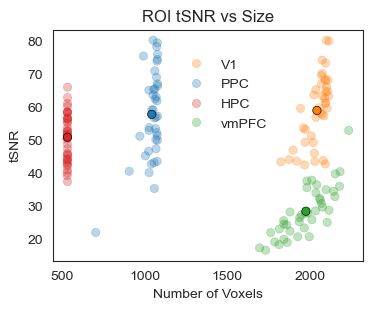

In [8]:
# plot tsnr against nvoxels
roi_hue_dict = dict(zip(
    roi_qc_df.region.unique(),
    sns.color_palette(None,len(roi_qc_df.region.unique()))
))
fig,ax = plt.subplots(figsize=(4,3))
# plot each sub
sns.scatterplot(
    data=roi_qc_df[roi_qc_df.subgroup=="Generalizer"],
    x="nvoxels",
    y="tsnr",
    hue="region",
    palette=roi_hue_dict,
    ax=ax,
    alpha=0.3,
    edgecolor=None,
)
# plot mean sub
sns.scatterplot(
    data=roi_qc_df[roi_qc_df.subgroup=="Generalizer"].groupby(["subgroup","region"])[["nvoxels","tsnr"]].mean().reset_index(),
    x="nvoxels",
    y="tsnr",
    hue="region",
    edgecolor="black",
    legend=False,
    palette=roi_hue_dict,
    ax=ax
)
# move legend outside
ax.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
# change the two legend titles in to "Region" and "Participant Group"
handles, labels = ax.get_legend_handles_labels()
new_labels = []
for label in labels:
    if label=="region":
        new_labels.append("Region")
    elif label=="subgroup":
        new_labels.append("Participant Group")
    else:
        new_labels.append(label)
ax.legend(handles, new_labels, bbox_to_anchor=(0.4, 0.9), loc=2, borderaxespad=0.,
          frameon=False)
ax.set_title("ROI tSNR vs Size")
ax.set_xlabel("Number of Voxels")
ax.set_ylabel("tSNR")
r, p = scipy.stats.pearsonr(roi_qc_df[roi_qc_df.subgroup=="Generalizer"]["nvoxels"], roi_qc_df[roi_qc_df.subgroup=="Generalizer"]["tsnr"])
print(f"Correlation between ROI size and tSNR: r={r:.3f}, p={p:.3f}")

## No correlation between dimensionality estimates and behaviour

In [12]:
# sanity checks
svdestdim_df_sum_wide = svdestdim_df_sum.pivot(index=["roi","subid","subgroup"],columns="dimonaxis",values="est_dim").reset_index()
subLLR_axismean = subsitm_LLR.groupby(['subid','training'])[["LLRx_trial","LLRy_trial","error_x","error_y"]].mean().reset_index()
svdestdim_df_sum_wide_beh = svdestdim_df_sum_wide.merge(subLLR_axismean[subLLR_axismean.subid.isin(generalizers)], on="subid", how="left")


In [12]:
dim_corrs = {
     "dimwithLLR":   "LLR%s_trial",
     "dimwithError": "error_%s"
}
res_df = pd.DataFrame()
for dimcorrname, behfeat_template in dim_corrs.items():
    for dim in ["x","y"]:
        xvar = f"{dim} axis"
        yvar = behfeat_template % dim
        for gnames, gdf in svdestdim_df_sum_wide_beh.groupby(["roi","subgroup","training"]):
            print(f"Computing {dimcorrname} for {dim} axis for {gnames}")
            dimcorr=correlation_equiv_permutation(
                gdf[xvar].values,
                gdf[yvar].values,
                corrfun=lambda x,y: scipy.stats.pearsonr(x,y).statistic,
                return_ponly=False
            )
            res_df = pd.concat([res_df,
                                pd.DataFrame({
                                    "corr_ana":dimcorrname,
                                    "axis":[dim],
                                    "roi":[gnames[0]],
                                    "subgroup":[gnames[1]],
                                    "stimgroup":[gnames[2]],
                                    "corrcoef":[dimcorr.statistic],
                                    "pval":[dimcorr.pvalue]
                                })],
                            ignore_index=True)
            
res_df["pval_fdr"] = res_df.groupby(["corr_ana","stimgroup","subgroup"])["pval"].transform(lambda x: fdrcorrection(x,is_sorted=False)[1])

Computing dimwithLLR for x axis for ('PPC_bilateral', 'Generalizer', 'test stimuli')
Computing dimwithLLR for x axis for ('PPC_bilateral', 'Generalizer', 'training stimuli')
Computing dimwithLLR for x axis for ('V1_bilateral', 'Generalizer', 'test stimuli')
Computing dimwithLLR for x axis for ('V1_bilateral', 'Generalizer', 'training stimuli')
Computing dimwithLLR for x axis for ('vmPFC_bilateral', 'Generalizer', 'test stimuli')
Computing dimwithLLR for x axis for ('vmPFC_bilateral', 'Generalizer', 'training stimuli')
Computing dimwithLLR for x axis for ('HPC_bilateral', 'Generalizer', 'test stimuli')
Computing dimwithLLR for x axis for ('HPC_bilateral', 'Generalizer', 'training stimuli')
Computing dimwithLLR for y axis for ('PPC_bilateral', 'Generalizer', 'test stimuli')
Computing dimwithLLR for y axis for ('PPC_bilateral', 'Generalizer', 'training stimuli')
Computing dimwithLLR for y axis for ('V1_bilateral', 'Generalizer', 'test stimuli')
Computing dimwithLLR for y axis for ('V1_bil

In [13]:
# see if difference in dim correlates with diff in error/LLR
svdestdim_df_sum_wide_beh["dim_diff"] = svdestdim_df_sum_wide_beh["x axis"] - svdestdim_df_sum_wide_beh["y axis"]
svdestdim_df_sum_wide_beh["llr_diff"] = svdestdim_df_sum_wide_beh["LLRx_trial"] - svdestdim_df_sum_wide_beh["LLRy_trial"]
svdestdim_df_sum_wide_beh["error_diff"] = svdestdim_df_sum_wide_beh["error_x"] - svdestdim_df_sum_wide_beh["error_y"]
dimdiff_corrs = {
     "dimdiff_withLLRdiff":   "llr_diff",
     "dimdiff_withErrordiff": "error_diff"
}
res_diff_df = pd.DataFrame()
for dimcorrname, behfeat in dimdiff_corrs.items():
        xvar = "dim_diff"
        yvar = behfeat
        for gnames, gdf in svdestdim_df_sum_wide_beh.groupby(["roi","subgroup","training"]):
            if gnames[0]=="vmPFC_bilateral" and gnames[1]=="Generalizer":
                print(f"Computing {dimcorrname} for {gnames}")
                dimcorr=correlation_equiv_permutation(
                    gdf[xvar].values,
                    gdf[yvar].values,
                    corrfun=lambda x,y: scipy.stats.pearsonr(x,y).statistic,
                    return_ponly=False
                )
                res_diff_df = pd.concat([res_diff_df,
                                    pd.DataFrame({
                                        "corr_ana":dimcorrname,
                                        "roi":[gnames[0]],
                                        "subgroup":[gnames[1]],
                                        "stimgroup":[gnames[2]],
                                        "corrcoef":[dimcorr.statistic],
                                        "pval":[dimcorr.pvalue]
                                    })],
                                ignore_index=True)
res_diff_df["pval_fdr"] = fdrcorrection(res_diff_df["pval"],is_sorted=False)[1]

Computing dimdiff_withLLRdiff for ('vmPFC_bilateral', 'Generalizer', 'test stimuli')
Computing dimdiff_withLLRdiff for ('vmPFC_bilateral', 'Generalizer', 'training stimuli')
Computing dimdiff_withErrordiff for ('vmPFC_bilateral', 'Generalizer', 'test stimuli')
Computing dimdiff_withErrordiff for ('vmPFC_bilateral', 'Generalizer', 'training stimuli')


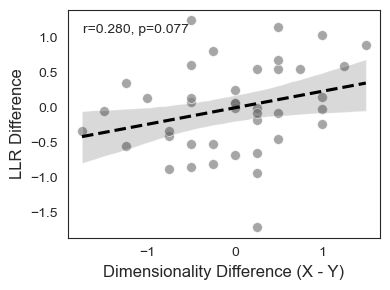

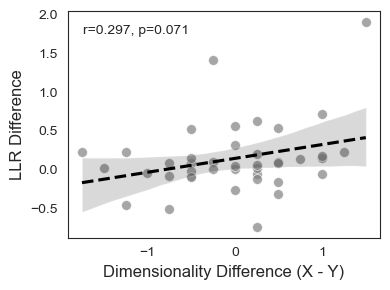

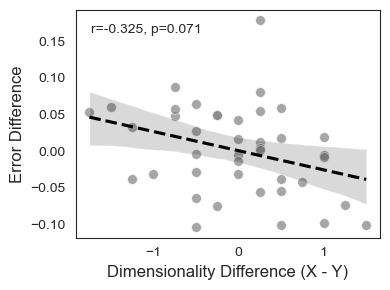

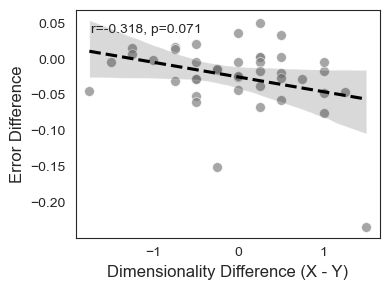

In [14]:
# plot the correlation using scatterplot for vmPFC and generalizers only
pval_diff_df = res_diff_df.copy()
for corr_ana in pval_diff_df.corr_ana.unique():
    for stimgroup in pval_diff_df.stimgroup.unique():
        fig, ax = plt.subplots(1,1, figsize=(4,3))
        plotdf = svdestdim_df_sum_wide_beh[
            (svdestdim_df_sum_wide_beh.roi=="vmPFC_bilateral") &
            (svdestdim_df_sum_wide_beh.subgroup=="Generalizer") &
            (svdestdim_df_sum_wide_beh.training==stimgroup)
        ].copy()
        sns.scatterplot(
            data=plotdf,
            x="dim_diff",
            y=dimdiff_corrs[corr_ana],
            s=50,
            color="grey",
            alpha=0.7,
            ax=ax
        )
        sns.regplot(
            data=plotdf,
            x="dim_diff",
            y=dimdiff_corrs[corr_ana],
            scatter=False,
            ax=ax,
            line_kws={"color":"black","linestyle":"--"}
        )
        # add correlation coefficient text 
        pval_row = pval_diff_df[
            (pval_diff_df.corr_ana==corr_ana) &
            (pval_diff_df.stimgroup==stimgroup)
        ]
        r = pval_row.corrcoef.values[0]
        p = pval_row.pval_fdr.values[0]
        ax.text(0.05, 0.9, f"r={r:.3f}, p={p:.3f}", transform=ax.transAxes, fontsize=10)
        ax.set_xlabel("Dimensionality Difference (X - Y)",**def_font_axis_legend_titles)
        ax.set_ylabel("LLR Difference" if corr_ana=='dimdiff_withLLRdiff' else "Error Difference",**def_font_axis_legend_titles)
        #fig.suptitle(f"{corr_ana} - {stimgroup}", **def_font_subplot_titles)
        fig.tight_layout()

Mean LLR for training stimuli: X axis: 1.313, Y axis: 1.312
Stat for training stimuli: mean=0.142, p=0.051
Mean LLR for test stimuli: X axis: 0.431, Y axis: 0.425
Stat for test stimuli: mean=-0.008, p=0.923


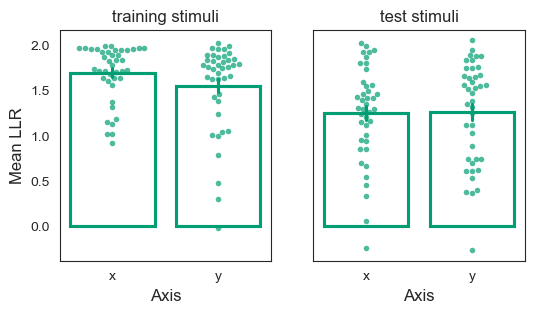

In [15]:
# use subLLR_axismean to plot the mean LLR for each axis
subLLR_axismean["training"] = pd.Categorical(
    subLLR_axismean["training"],
    categories=["training stimuli","test stimuli"],
    ordered=True
)
fig, axes = plt.subplots(1,2, figsize=(6,3),sharey=True)
for k, (sg, sgdf) in enumerate(subLLR_axismean.groupby("training")):
    ax = axes[k]
    sgdf_melt = sgdf.melt(id_vars=["subid"], value_vars=["LLRx_trial","LLRy_trial"],
                         var_name="axis", value_name="LLR")
    sgdf_melt["axis"] = sgdf_melt["axis"].map({"LLRx_trial":"x","LLRy_trial":"y"})
    sgdf_melt=sgdf_melt[sgdf_melt.subid.isin(generalizers)].copy()
    sns.swarmplot(
        data=sgdf_melt,
        x="axis",
        y="LLR",    
        s=4,
        alpha=0.7,
        ax=ax,
        color=participantgrouphex["Generalizer"]
    )
    sns.barplot(
        data=sgdf_melt,
        x="axis",
        y="LLR",
        errorbar="se",
        fill=False, 
        color=participantgrouphex["Generalizer"],
        ax=ax
    )
    # do stats
    statres = ttestpairedsamp_equiv_permutation(
        sgdf_melt[sgdf_melt.axis=="x"]["LLR"].values,
        sgdf_melt[sgdf_melt.axis=="y"]["LLR"].values,
        return_ponly=False
    )
    #pval_annot = gen_pval_annot(statres.pvalue, show_pval=True)
    # add stat annotation
    #ax.text(0.5, max(sgdf_melt["LLR"])*0.9, pval_annot, ha='center', fontsize=12)
    ax.set_xlabel("Axis",**def_font_axis_legend_titles)
    ax.set_ylabel("Mean LLR",**def_font_axis_legend_titles) 
    ax.set_title(f"{sg}",**def_font_axis_legend_titles)
    print(f"Mean LLR for {sg}: X axis: {sgdf['LLRx_trial'].mean():.3f}, Y axis: {sgdf['LLRy_trial'].mean():.3f}")
    print(f"Stat for {sg}: mean={statres.statistic:.3f}, p={statres.pvalue:.3f}")

# Geometry: Parallel vs Orthogonal Axis


Plots related to geometry, i.e., how the two rules are represented with respect to each other (Figure 3 of the main text). Make sure that the [`PTAregRSAtwofold.py`](multivariate/PTAregRSAtwofold.py), as well as the two MDS scripts [`computeAxisPS_navi.py`](multivariate/computeAxisPS_navi.py) and [`dimreduc_MDS_parallelaxisgroups.py`](multivariate/dimreduc_MDS_parallelaxisgroups.py) have been executed before running the plotting scripts in this section.




In [16]:
# load CVRSA results
PTAregRSA_CVres = load(os.path.join(ROIRSAdir,'axisPS','cvRSA',"ROI_PTARSA_2v2.pkl"))
PTAregRSA_CVres.keys()
ROIRSA_PTA_cvres = pd.concat(PTAregRSA_CVres["RSA"],axis=0).reset_index(drop=True)
#ROIRSA_PTA_cvres = ROIRSA_PTA_cvres[~ROIRSA_PTA_cvres.subid.isin (["sub129","sub010"])].copy()  # remove sub129 who has incomplete data
ROIRSA_PTA_cvres.head(5)
ROIRSA_PTA_cvres_meandf = ROIRSA_PTA_cvres.groupby([ 'PSGROUProi', 'analysis', 'subid', 'modelrdm'])[['adjR2', 'R2', 'coefficient']].mean().reset_index()
ROIRSA_PTA_cvres_meandf["subgroup"] = ["Generalizer" if subid in generalizers else "nonGeneralizer" for subid in ROIRSA_PTA_cvres_meandf["subid"]]

# load precalculated PS and null distribution of PS
ROIPS_dict = load(os.path.join(ROIRSAdir,"axisPS","PS_NCtrainingstim.pkl"))
sub_cs_perms, sub_cs_obs = ROIPS_dict["permutation"], ROIPS_dict["observation"]
PS_classification = pd.read_csv(os.path.join(ROIRSAdir,"axisPS","PS_classification.csv"))
PS_classification["subgroup"] = pd.Categorical(
    ["Generalizers" if subid in generalizers else "nonGeneralizers" for subid in PS_classification["subid"]],
    categories=["Generalizers","nonGeneralizers"],ordered=True)
PS_classification["subcohort"] = pd.Categorical(
    ["First Cohort" if subid in cohort1ids else "Second Cohort" for subid in PS_classification["subid"]],
    categories=["First Cohort","Second Cohort"],ordered=True)

# load MDS results
## for all stimuli
rdm_mds_results = load(os.path.join(ROIRSAdir,"mds_results_rescaled.pkl"))
## for non-centre training stimuli
PSAXrdm_mds_results = load(os.path.join(ROIRSAdir,'axisPS','MDS',"ParallAx_nonmetricmds_results.pkl")) # nonmetric_



In [17]:
parallelorthogonalfit_subdf = ROIRSA_PTA_cvres_meandf[(ROIRSA_PTA_cvres_meandf.analysis=='train stim Compete PTAOrthohighlow')].copy().reset_index(drop=True)
print(parallelorthogonalfit_subdf.modelrdm.unique())
parallelorthogonalfit_subdf = parallelorthogonalfit_subdf[parallelorthogonalfit_subdf.PSGROUProi!="M1_left"].copy().reset_index(drop=True)
parallelorthogonalfit_subdf["modelrdm_shortname"] = pd.Categorical(
    parallelorthogonalfit_subdf["modelrdm"].map(
        {"ortho_high":"ortho.\nhighD",
         "ortho_low":"ortho.\nlowD",
         "PTA_high":"parallel\nhighD",
         "PTA_low":"parallel\nlowD",
         }
    ),
    categories=['ortho.\nhighD', 'ortho.\nlowD','parallel\nhighD', 'parallel\nlowD']
)   
print(parallelorthogonalfit_subdf.head(3))
parallelorthogonalfit_subdf.PSGROUProi = pd.Categorical(
    parallelorthogonalfit_subdf.PSGROUProi, 
    categories=["V1_bilateral","PPC_bilateral", "HPC_bilateral", "vmPFC_bilateral"],
    ordered=True
)

['PTA_high' 'PTA_low' 'ortho_high' 'ortho_low']
      PSGROUProi                            analysis   subid    modelrdm  \
0  HPC_bilateral  train stim Compete PTAOrthohighlow  sub001    PTA_high   
1  HPC_bilateral  train stim Compete PTAOrthohighlow  sub001     PTA_low   
2  HPC_bilateral  train stim Compete PTAOrthohighlow  sub001  ortho_high   

    adjR2        R2  coefficient     subgroup modelrdm_shortname  
0 -0.0182  0.094933     0.263466  Generalizer    parallel\nhighD  
1 -0.0182  0.094933    -0.096064  Generalizer     parallel\nlowD  
2 -0.0182  0.094933    -0.087811  Generalizer      ortho.\nhighD  


## No significant relationship between Parallelism and behavioural metrics

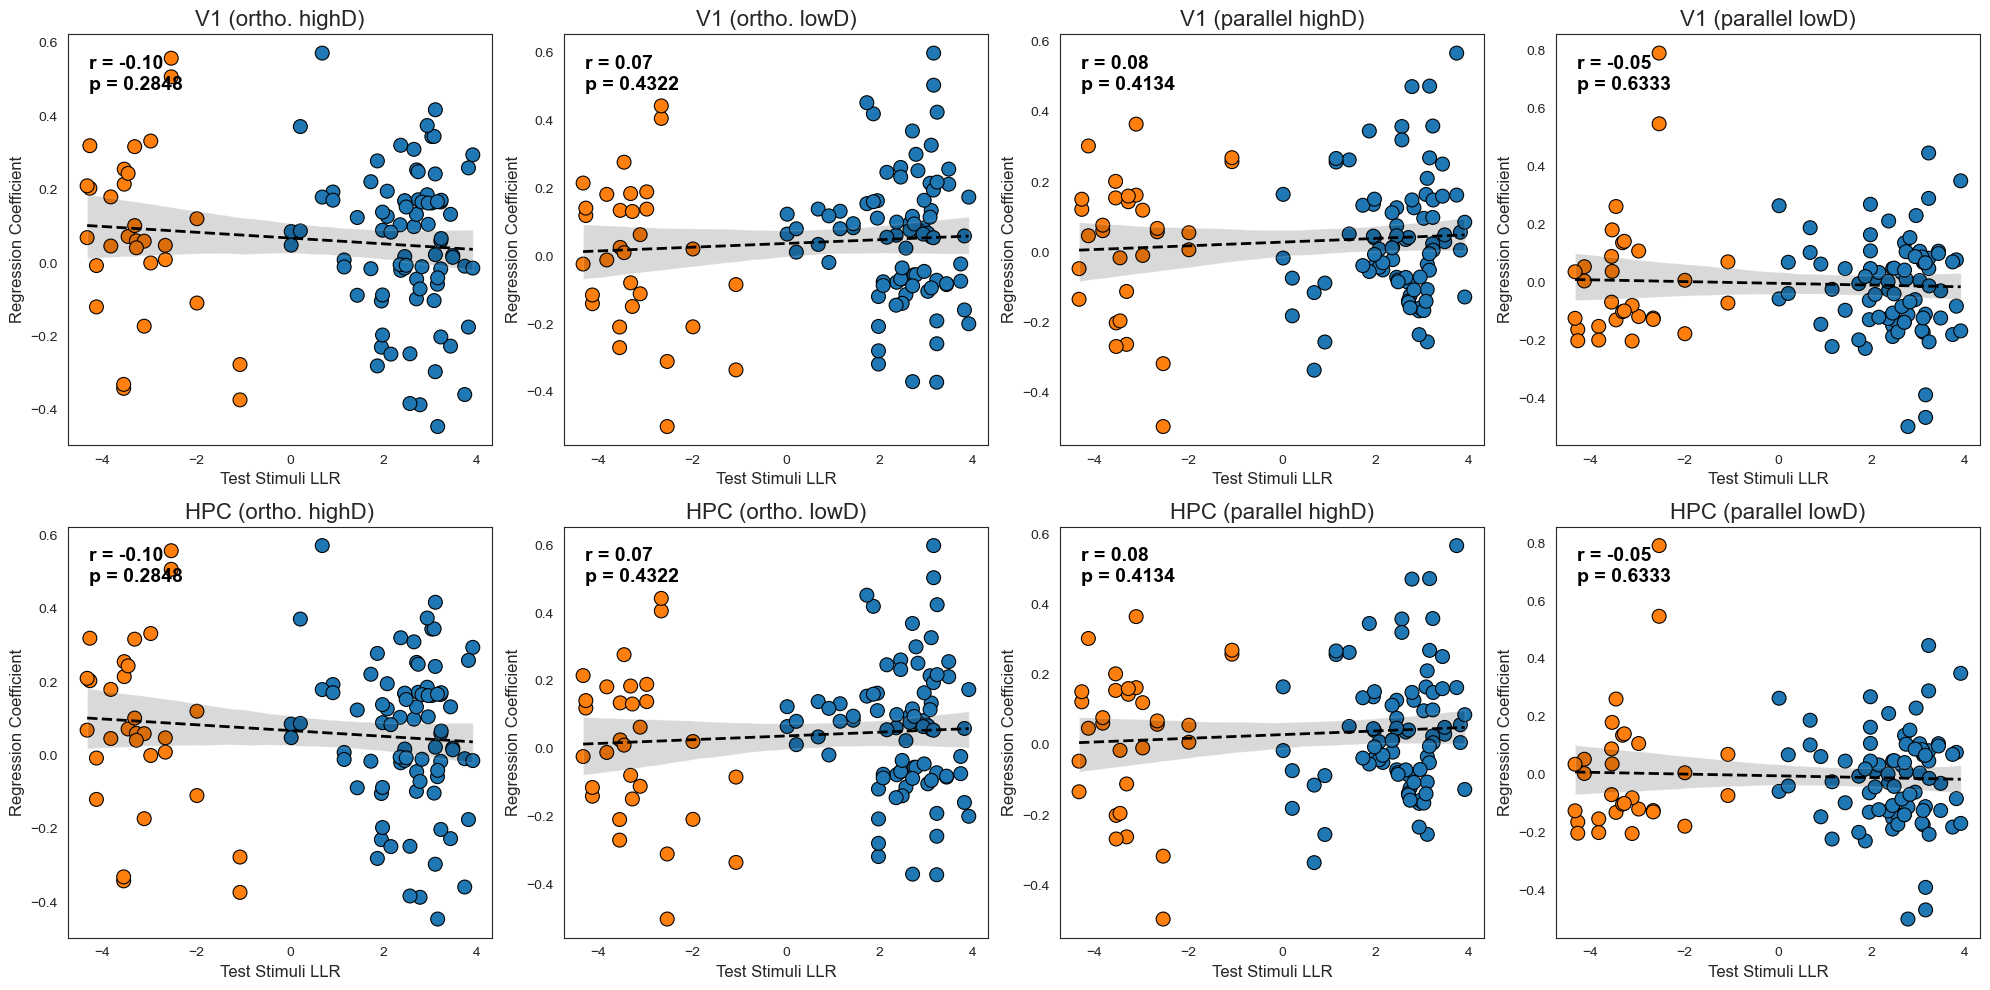

In [20]:
# merge compositionretrieval with subLLR_mean_wide to see LLR correlation
subLLR_mean_wide = subLLR_mean.pivot(index="subid",columns="training",values="LLR").reset_index()
subLLR_mean_wide.rename(columns={"test stimuli":"testLLR","training stimuli":"trainLLR"},inplace=True)
parallelorthogonalfit_subdf_v1hpc = parallelorthogonalfit_subdf[parallelorthogonalfit_subdf.PSGROUProi.isin(["V1_bilateral","HPC_bilateral"])].copy().reset_index(drop=True)
parallelorthogonalfit_subdf_v1hpc.PSGROUProi = pd.Categorical(
    parallelorthogonalfit_subdf_v1hpc.PSGROUProi, 
    categories=["V1_bilateral", "HPC_bilateral"],
    ordered=True
)
parallelorthogonalfit_subdf_v1hpc = parallelorthogonalfit_subdf_v1hpc.merge(subLLR_mean_wide[["subid","trainLLR","testLLR"]],on=["subid"],how="left")
parallelorthogonalfit_subdf_v1hpc
# plot correlation between beta and LLR
fig, axes = plt.subplots(2,4,figsize=(20,10))
for krow, (roi, roidf) in enumerate(parallelorthogonalfit_subdf_v1hpc.groupby("PSGROUProi")):
    for kcol, (mname, mdf) in enumerate(parallelorthogonalfit_subdf_v1hpc.groupby("modelrdm_shortname")):
        ax = axes[krow, kcol]
        axdf = mdf.copy().reset_index(drop=True)
        sns.scatterplot(
            data=axdf,
            x="testLLR",y="coefficient", hue="subgroup",
            s=100,edgecolor="black",linewidth=0.8,
            ax=ax
        )
        sns.regplot(
            data=axdf,
            x="testLLR",y="coefficient", scatter=False,
            color="black",
            line_kws={"linewidth":2,"linestyle":"--"},
            ax=ax
        )
        # compute pearson correlation
        r, pval = scipy.stats.pearsonr(axdf["testLLR"],axdf["coefficient"])
        ax.text(0.05, 0.95,
                s=f"r = {'%.2f' % r}\np = {'%.4f' % pval}",
                fontsize=14,fontweight="bold",color="black",
                ha="left",va="top",transform=ax.transAxes)
        mnamenew = mname.replace("\n"," ")
        ax.set_title(f"{roi_shortnames[roi]} ({mnamenew})",
                     fontdict=def_font_subplot_titles)   
        ax.set_ylabel("Regression Coefficient",fontdict=def_font_axis_legend_titles)
        ax.set_xlabel("Test Stimuli LLR",fontdict=def_font_axis_legend_titles)
        ax.tick_params(labelleft=True, labelbottom=True)
        ax.xaxis.label.set_visible(True)
        ax.yaxis.label.set_visible(True)
        #remove legend
        ax.legend().remove()
fig.tight_layout(w_pad=1)

# Control analysis for retrieval pattern analysis
## plot the shuffle method

In [13]:
shuffle_method = "factorised" # the method to shuffle locations, see pirateOMutils.shuffle_locations for options
share_seeds = True # whether to use the same seed across participants for each iteration
withintaskrsadir = os.path.join(ROIRSAdir,"withintaskrsa")
shuffled_dir = os.path.join(withintaskrsadir,f"{shuffle_method}_{'sharedseeds' if share_seeds else 'diffseeds'}_null")
n_shuffles = 10000

In [14]:
from scripts.Exp1_fmri.multivariate.pirateOMutils import shuffle_locations

locations = itertools.product(
    [-2,-1,0,1,2],
    [-2,-1,0,1,2]
)
locations = np.array(list(locations))
stimdf = pd.DataFrame(locations,columns=["stim_x","stim_y"])
stimdf["stim_name"] = ["%d,%d"%(x,y) for x,y in stimdf[["stim_x","stim_y"]].to_numpy()]
stimdf["stimgroup"] = ["training" if x*y==0 else "test" for x,y in stimdf[["stim_x","stim_y"]].to_numpy()]
test_df = stimdf[stimdf.stimgroup=="test"].copy()
test_df_shuffled = test_df.copy()
training_df = stimdf[stimdf.stimgroup=="training"].copy()
training_df_shuffled = training_df.copy()

# shuffle the test locations first
stimgtlocs = np.copy(test_df[["stim_x","stim_y"]].to_numpy())
shufffled_locs, (x_map, y_map) = shuffle_locations(stimgtlocs, shuffle_function="factorised", randomseed=1352, return_mapping=True,force_different=True)
test_df_shuffled[["shuffled_stim_x","shuffled_stim_y"]] = shufffled_locs            
print("x_map: ", x_map)
print("y_map: ", y_map)
x_map[0.0], y_map[0.0] = 0.0, 0.0 # need to keep the central location unchanged
# then we apply the same x_map and y_map to training stimuli df
traingtlocs = training_df[["stim_x","stim_y"]].to_numpy()
shuffled_trlocs = np.array([[x_map[x], y_map[y]] for x, y in traingtlocs])
training_df_shuffled[["shuffled_stim_x","shuffled_stim_y"]] = shuffled_trlocs

training_df_shuffled

x_map:  {-2: 1, -1: 2, 1: -2, 2: -1}
y_map:  {-2: -1, -1: 1, 1: 2, 2: -2}


,stim_x,stim_y,stim_name,stimgroup,shuffled_stim_x,shuffled_stim_y
2,-2,0,"-2,0",training,1.0,0.0
7,-1,0,"-1,0",training,2.0,0.0
10,0,-2,"0,-2",training,0.0,-1.0
11,0,-1,"0,-1",training,0.0,1.0
12,0,0,"0,0",training,0.0,0.0
13,0,1,"0,1",training,0.0,2.0
14,0,2,"0,2",training,0.0,-2.0
17,1,0,"1,0",training,-2.0,0.0
22,2,0,"2,0",training,-1.0,0.0


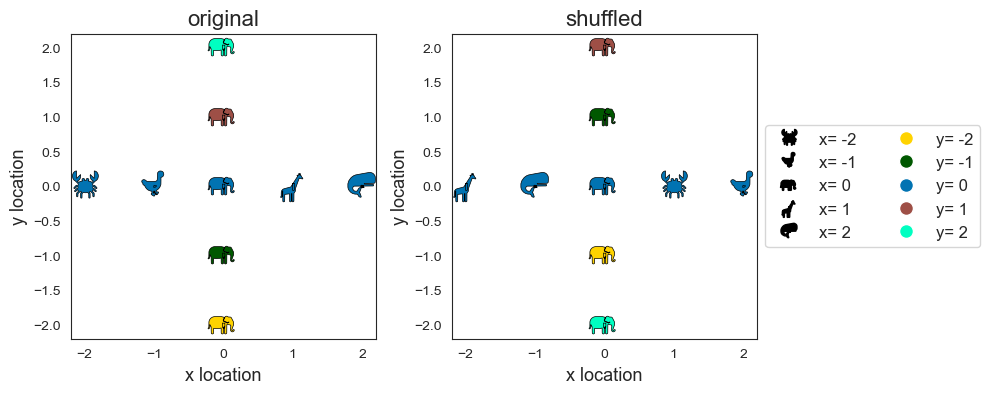

In [15]:

training_df_shuffled["stim_name"] = ["%d,%d"%(x,y) for x,y in training_df_shuffled[["stim_x","stim_y"]].to_numpy()]
# plot two subplots side by side, one for the original training locations, one for the shuffled training locations
fig, axes = plt.subplots(1,2,figsize=(10,7),sharex=False,sharey=False)

# Plot each group with different color and marker
for (stim_x, stim_y), group in training_df_shuffled.groupby(['stim_x', 'stim_y']):
    axes[0].scatter(group['stim_x'], group['stim_y'],
            color=stimycolorhex[stim_y], marker=stimxanimalmarkers[stim_x],
            s=500,edgecolor='black',linewidth=0.5)
    axes[1].scatter(group['shuffled_stim_x'], group['shuffled_stim_y'],
            color=stimycolorhex[stim_y], marker=stimxanimalmarkers[stim_x],
            s=500,edgecolor='black',linewidth=0.5,
            label=f'{stim_x},{stim_y}')

# Create custom legends
color_legend = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=stimycolorhex[i], markersize=10, label='y= %d'%(i))
                for i in np.sort(training_df_shuffled["stim_y"].unique())]
marker_legend = [plt.Line2D([0], [0], marker=stimxanimalmarkers[i], color='k', markerfacecolor='k',linewidth=0, markersize=13, label='x= %d'%(i)) 
                 for i in np.sort(training_df_shuffled["stim_x"].unique())]

# Set plot title and labels
axes[0].set_title("original",fontdict=def_font_subplot_titles) # - {cname} Generalizers
axes[1].set_title("shuffled",fontdict=def_font_subplot_titles) # - {cname} Generalizers
for ax in axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x location',fontdict={"size":13})   
    ax.set_ylabel('y location',fontdict={"size":13})

# one legend for both subplots
axes[1].legend(handles=marker_legend + color_legend, 
          loc='center left', 
          bbox_to_anchor=(1, 0.5),
          ncol=2,
          fontsize=def_font_axis_legend_titles["fontsize"])


# Adjust the axis limits to avoid cropping
fig.tight_layout()
plt.show()


In [16]:
from scripts.Exp1_fmri.multivariate.pirateOMutils import shuffle_locations

locations = itertools.product(
    [-2,-1,0,1,2],
    [-2,-1,0,1,2]
)
locations = np.array(list(locations))
stimdf = pd.DataFrame(locations,columns=["stim_x","stim_y"])
stimdf["stim_name"] = ["%d,%d"%(x,y) for x,y in stimdf[["stim_x","stim_y"]].to_numpy()]
stimdf["stimgroup"] = ["training" if x*y==0 else "test" for x,y in stimdf[["stim_x","stim_y"]].to_numpy()]
stimdf_shuffled = stimdf.copy()
test_df = stimdf[stimdf.stimgroup=="test"].copy()

# shuffle the test locations first
stimgtlocs = np.copy(test_df[["stim_x","stim_y"]].to_numpy())
shufffled_locs, (x_map, _) = shuffle_locations(stimgtlocs, shuffle_function="factorised", randomseed=1352, return_mapping=True,force_different=True)
y_map = x_map
print("x_map: ", x_map)
print("y_map: ", y_map)
x_map[0.0], y_map[0.0] = 0.0, 0.0 # need to keep the central location unchanged
# then we apply the same x_map and y_map to whole stimdf
shuffled_stimlocs = np.array([[x_map[x], y_map[y]] for x, y in stimdf[["stim_x","stim_y"]].to_numpy()])
stimdf_shuffled[["shuffled_stim_x","shuffled_stim_y"]] = shuffled_stimlocs

stimdf_shuffled

x_map:  {-2: 1, -1: 2, 1: -2, 2: -1}
y_map:  {-2: 1, -1: 2, 1: -2, 2: -1}


,stim_x,stim_y,stim_name,stimgroup,shuffled_stim_x,shuffled_stim_y
0,-2,-2,"-2,-2",test,1.0,1.0
1,-2,-1,"-2,-1",test,1.0,2.0
2,-2,0,"-2,0",training,1.0,0.0
3,-2,1,"-2,1",test,1.0,-2.0
4,-2,2,"-2,2",test,1.0,-1.0
5,-1,-2,"-1,-2",test,2.0,1.0
6,-1,-1,"-1,-1",test,2.0,2.0
7,-1,0,"-1,0",training,2.0,0.0
8,-1,1,"-1,1",test,2.0,-2.0
9,-1,2,"-1,2",test,2.0,-1.0


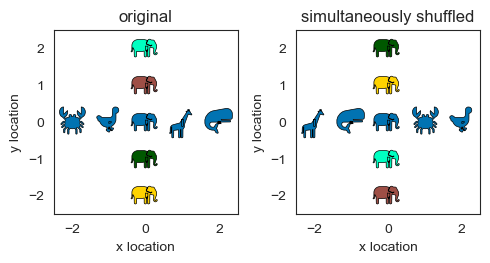

In [17]:

stimdf_shuffled["stim_name"] = ["%d,%d"%(x,y) for x,y in stimdf_shuffled[["stim_x","stim_y"]].to_numpy()]
# plot two subplots side by side, one for the original training locations, one for the shuffled training locations
fig, axes = plt.subplots(1,2,figsize=(5,3),sharex=False,sharey=False)

# Plot each group with different color and marker
for (stim_x, stim_y), group in stimdf_shuffled[stimdf_shuffled.stimgroup=="training"].groupby(['stim_x', 'stim_y']):
    axes[0].scatter(group['stim_x'], group['stim_y'],
            color=stimycolorhex[stim_y], marker=stimxanimalmarkers[stim_x],
            s=500,edgecolor='black',linewidth=0.5)
    axes[1].scatter(group['shuffled_stim_x'], group['shuffled_stim_y'],
            color=stimycolorhex[stim_y], marker=stimxanimalmarkers[stim_x],
            s=500,edgecolor='black',linewidth=0.5,
            label=f'{stim_x},{stim_y}')

# Create custom legends
color_legend = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=stimycolorhex[i], markersize=10, label='y= %d'%(i))
                for i in np.sort(training_df_shuffled["stim_y"].unique())]
marker_legend = [plt.Line2D([0], [0], marker=stimxanimalmarkers[i], color='k', markerfacecolor='k',linewidth=0, markersize=13, label='x= %d'%(i)) 
                 for i in np.sort(training_df_shuffled["stim_x"].unique())]

# Set plot title and labels
axes[0].set_title("original",fontdict=def_font_axis_legend_titles) # - {cname} Generalizers
axes[1].set_title("simultaneously shuffled",fontdict=def_font_axis_legend_titles) # - {cname} Generalizers
for ax in axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x location',fontdict={"size":10})   
    ax.set_ylabel('y location',fontdict={"size":10})
    ax.set_xlim([-2.5,2.5])
    ax.set_ylim([-2.5,2.5])

# Adjust the axis limits to avoid cropping
fig.tight_layout()
plt.show()


## retrieval pattern analysis shuffled results

In [13]:
resultdir = os.path.join(ROIRSAdir,"retrievalpatternCV")
resoverview_dir = os.path.join(resultdir,"resoverview")
shuffle_args = {
    "shuffle_function":"factorised", # "fullrand" or "factorised"
    "shared_seeds": True,
    "n_shuffles": 10000
    }
# get shorthand names for file saving
sf = shuffle_args["shuffle_function"]
ss = shuffle_args["shared_seeds"]
ss_str = 'sharedseeds' if ss else 'diffseeds'
n_shuffles = shuffle_args["n_shuffles"]
if n_shuffles <= 9999:
    ss_str = f"{ss_str}_nshuffles{n_shuffles:04d}"
    shuffleoutputprefix = "shuffle%04d"
elif n_shuffles <= 99999:
    ss_str = f"{ss_str}_nshuffles{n_shuffles:05d}"
    shuffleoutputprefix = "shuffle%05d"
else:
    raise ValueError("n_shuffles is too large, please keep it under 100000")

In [14]:
res = load(os.path.join(resoverview_dir,"retrievalpatternCV_results_withnull.pkl"))
resoverview_df = res["results"]
resoverview_df[["analysis","metricname"]] = resoverview_df.metric.str.split("-",expand=True)
resoverview_df["subgroup"] = ["Generalizer" if subid in generalizers else "nonGeneralizer" for subid in resoverview_df.subid]

null_res_df = res["null_results"]
reg_coefs = res["coefs"]
##################################################### plot the results for a quick check ##################################################### 
#resoverview_df["subgroup"] = pd.Categorical(resoverview_df["subgroup"],categories=["Generalizer","nonGeneralizer"],ordered=True)
checkmetrics = ["eval_corr","eval_r2","compoweight","meanweightdiff","reg_percept","reg_distmod"]
trtepred_df = resoverview_df[(resoverview_df.analysis=="train2test")&(resoverview_df.metricname.isin(checkmetrics))].copy()
trtepred_df.metricname = pd.Categorical(trtepred_df.metricname, categories=checkmetrics,ordered=True)
trtepred_nulldf = null_res_df[(null_res_df.analysis=="train2test")&(null_res_df.metricname.isin(checkmetrics))].copy()
trtepred_nulldf.metricname = pd.Categorical(trtepred_nulldf.metricname, categories=checkmetrics,ordered=True)

# plot the distribution of true against null
# first we create a dataframe that contains both true and null results
truedf = trtepred_df.assign(resulttype="true",shuffle_idx=-1)
nulldf = trtepred_nulldf.assign(resulttype="null")
truedf["roi"] = pd.Categorical(
    truedf.roi.map(lambda x: x.replace("_bilateral","")),
    categories=["V1","PPC","HPC","vmPFC"],
    ordered=True
)
nulldf["roi"] = pd.Categorical(
    nulldf.roi.map(lambda x: x.replace("_bilateral","")),
    categories=["V1","PPC","HPC","vmPFC"],
    ordered=True
)




In [15]:
from statsmodels.stats.multitest import fdrcorrection
def permutation_pval(trueval, nullvals, alternative="greater"):
    if alternative == "greater":
        pval = 1 - np.mean(trueval > nullvals)
    elif alternative == "less":
        pval = 1 - np.mean(trueval < nullvals)
    elif alternative == "two-sided":
        mean_null = np.mean(nullvals)
        pval = (np.sum(np.abs(nullvals-mean_null) >= np.abs(trueval-mean_null)) + 1) / (len(nullvals) + 1)
    else:
        raise ValueError("alternative must be 'greater', 'less', or 'two-sided'")
    return pval

Adjusted pval for  Generalizer reg_percept 0 PPC :  mean= 0.01532427073254307 pval= 0.0002999700029997001
Generalizer reg_percept [('PPC', 0.01532427073254307, 0.051085035856229, 9.999000099990002e-05), ('V1', 0.2223278118949692, 0.26309831635483405, 0.0024997500249975004), ('vmPFC', 0.03895765309590531, 0.05041165081482078, 0.252974702529747)]
Adjusted pval for  Generalizer reg_percept 1 V1 :  mean= 0.2223278118949692 pval= 0.003749625037496251
Generalizer reg_percept [('PPC', 0.01532427073254307, 0.051085035856229, 9.999000099990002e-05), ('V1', 0.2223278118949692, 0.26309831635483405, 0.0024997500249975004), ('vmPFC', 0.03895765309590531, 0.05041165081482078, 0.252974702529747)]
Generalizer reg_percept [('PPC', 0.01532427073254307, 0.051085035856229, 9.999000099990002e-05), ('V1', 0.2223278118949692, 0.26309831635483405, 0.0024997500249975004), ('vmPFC', 0.03895765309590531, 0.05041165081482078, 0.252974702529747)]
Adjusted pval for  Generalizer reg_distmod 0 PPC :  mean= 0.05911425

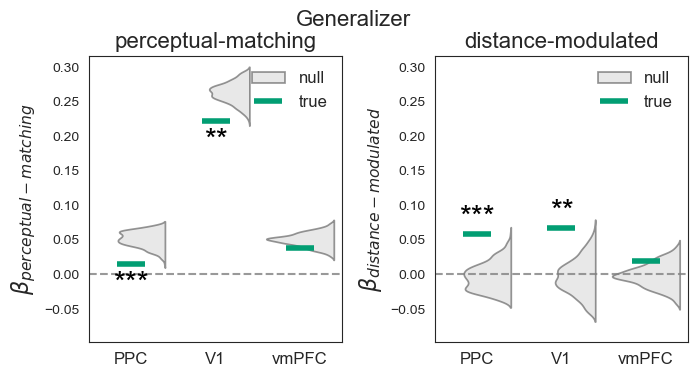

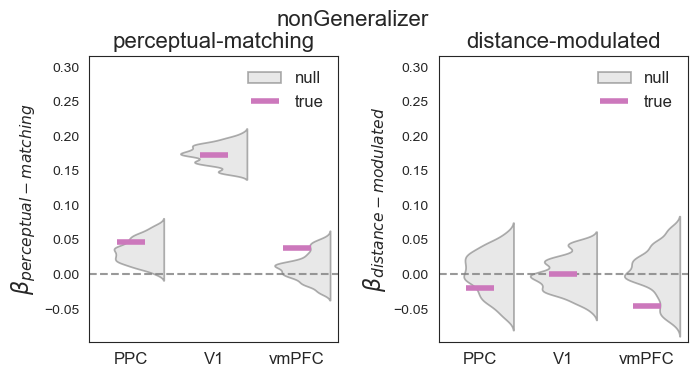

In [19]:
# show both groups
true_regcoef_df = truedf[truedf.metricname.isin(["reg_percept","reg_distmod"])].copy()
null_regcoef_df = nulldf[nulldf.metricname.isin(["reg_percept","reg_distmod"])].copy()
true_regcoef_df = true_regcoef_df[true_regcoef_df.roi.isin(["V1","PPC","vmPFC"])].copy()
null_regcoef_df = null_regcoef_df[null_regcoef_df.roi.isin(["V1","PPC","vmPFC"])].copy()
true_regcoef_df["roi"] = true_regcoef_df.roi.cat.remove_categories(["HPC"])
null_regcoef_df["roi"] = null_regcoef_df.roi.cat.remove_categories(["HPC"])
xvar, yvar, huevar = "roi", "value", "resulttype"
ymin,ymax, axes_set, fig_set = [], [], [], []
colvar, rowvar = "metricname","subgroup"
for _, (sgname,sgdf_true) in enumerate(true_regcoef_df.groupby(rowvar)):
    sgdf_true[colvar] = sgdf_true[colvar].cat.remove_unused_categories()
    ncol, nrow = sgdf_true[colvar].nunique(), sgdf_true[rowvar].nunique()
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.5*ncol,4*nrow),
                            squeeze=False, sharex=False, sharey=False)#
    for j, (gname,gdf_true) in enumerate(sgdf_true.groupby(colvar)):
        ax = axes.flatten()[j]
        # add a dashed grey line at zero
        ax.axhline(y=0, linestyle="--", color="grey", alpha=0.8)

        gdf_null = null_regcoef_df[
            (null_regcoef_df[colvar]==gname) &
            (null_regcoef_df[rowvar]==sgname)
        ]
        
        palettes = dict(zip(["true","null"],
                        [participantgrouphex[sgname],"lightgrey"]
                        ))
        sns.violinplot(data=gdf_null, x=xvar, y=yvar, hue=huevar, palette=palettes, 
                        split=True, fill=True, ax=ax,alpha=0.5,
                        bw_adjust=1.5,
                        inner=None)
        
        sns.pointplot(data=gdf_true, x=xvar, y=yvar, hue=huevar, 
                      palette=palettes, ax=ax, errorbar=None, markers="_", linestyles="",
                      markersize=20,
                      markeredgewidth=4)
        model_names = {
            "reg_percept":"perceptual-matching",
            "reg_distmod":"distance-modulated",
        }
        mname_full = model_names[gname]
        ax.set_title(f"{mname_full}",**def_font_subplot_titles)
        ax.set_ylabel(r'$\beta_{'+mname_full+'}$',fontdict=def_font_subplot_titles)
        ax.set_xlabel("")
        plt.setp(ax.get_xticklabels(),
            rotation=0,ha="center",
            **def_font_axis_legend_titles)

        pvals_plot = []
        for t in gdf_true.roi.unique():
            gdf_true_roi = gdf_true[gdf_true.roi==t].copy()
            gdf_null_roi = gdf_null[gdf_null.roi==t].copy()    
            truevals = gdf_true_roi.value.values
            nullvals = gdf_null_roi.value.values
            mu_true = np.mean(truevals)
            # compute two-sided pval
            pval = permutation_pval(mu_true, nullvals, alternative="two-sided")
            pvals_plot.append((t, mu_true,nullvals.mean(), pval))
        # fdr correction of pvals    
        pval_adjusted = fdrcorrection([x[3] for x in pvals_plot])[1]
        for (t, mu_true,mu_null, _), pval in zip(pvals_plot,pval_adjusted):
            i = list(gdf_true.roi.cat.categories).index(t)
            # add stars
            if pval < 0.001:
                star = '***'
            elif pval < 0.01:
                star = '**'
            elif pval < 0.05:
                star = '*'
            else:
                star = ''
            if star != '':
                print("Adjusted pval for ", sgname, gname, i, t, ": ", "mean=",mu_true, "pval=",pval)
            if mu_true<mu_null:
                ax.text(i, mu_true - 0.01, star, ha='center', va='top', color='k', fontsize=22)
            else:
                ax.text(i, mu_true + 0.001, star, ha='center', va='bottom', color='k', fontsize=22)
            sns.move_legend(ax, "best", title="", ncol=1,frameon=False,
                            fontsize=def_font_axis_legend_titles["fontsize"])
            print(sgname,gname,pvals_plot)

    axes_set.append(axes) 
    fig.suptitle(sgname,**def_font_subplot_titles,y=0.93)
    fig.tight_layout()
    fig_set.append(fig)

    # compute a shared y axis limit across all subplots
    ymax.append(max([ax.get_ylim()[1] for ax in axes.flatten()]))
    ymin.append(min([ax.get_ylim()[0] for ax in axes.flatten()]))

# set the same y axis limit for all subplots
ymin_final = min(ymin)
ymax_final = max(ymax)
for axes in axes_set:
    for j,ax in enumerate(axes.flatten()):
        ax.set_ylim([ymin_final, ymax_final])
        # for the last figure in each row add text to annotate that p-values are fdr corrected
        if j == 4:#j % ncol == ncol - 1:
            ax.text(ax.get_xlim()[1], ax.get_ylim()[0] - 0.1 * (ax.get_ylim()[1] - ax.get_ylim()[0]), 
                    "p-values are FDR corrected across ROIs", ha='right', va='top', color='k', fontsize=10)
fig_set[0].savefig(os.path.join(ROIRSAdir,"finalfigs","figS4e.tif"),dpi=300,bbox_inches="tight")
fig_set[1].savefig(os.path.join(ROIRSAdir,"finalfigs","figS4f.tif"),dpi=300,bbox_inches="tight")

# Localizer task behaviour performance

In [21]:
beh_dir = os.path.join(project_path,"data","Exp1_fmri","fmri","beh")
lzer_bhav = pd.DataFrame()
for subid in subid_list:
    subnum = subid.replace("sub","")
    behfile = os.path.join(beh_dir,subid,f"sub-{subnum}_task-localizer_run-1_onsets.csv")
    behdf = pd.read_csv(behfile).assign(subid=subid)
    behdf.sort_values(by="onset_stimuli",inplace=True)
    behdf["trialid"] = range(1, len(behdf) + 1)
    #add sameasprev column by comparing stim_id with the previous trial
    behdf["sameasprev"] = behdf["stim_id"].shift(1) == behdf["stim_id"]
    # set the first trial of sameasprev to nan
    behdf.loc[behdf.trialid==1,"sameasprev"] = np.nan
    
    # compute accuracy to double check: response should be 1 if sameasprev is true, otherwise response should be nan
    # to see if matches with the original column
    acc = ((behdf["sameasprev"]==True) & (behdf["response"]==1)) | ((behdf["sameasprev"]==False) & (behdf["response"].isna()))
    acc = acc.values*1.
    # first trial accuracy is nan, leave out for comparison
    assert np.array_equal(acc[1:], behdf["acc"].values[1:])

    behdf["response_time"] = [x if ~np.isnan(responset) else np.nan for (x, responset) in behdf[["duration_stimuli","onset_response"]].to_numpy()]
    behdf = behdf[["subid","trialid","stim_id","stim_x","stim_y","sameasprev","response","acc","response_time"]].copy()

    lzer_bhav = pd.concat([lzer_bhav, behdf], ignore_index=True)
lzer_bhav.to_csv(os.path.join(project_path,"data","Exp1_fmri","localiser_task_perf_excfirsttrial.csv"))

In [22]:
lzer_bhav["response_time"].describe()

count    984.000000
mean       0.650336
std        0.199521
min        0.001007
25%        0.551994
50%        0.661853
75%        0.781863
max        0.989616
Name: response_time, dtype: float64

In [23]:
# compute TSNR metrics:
# correct pressed when there it is the same as before
# correct not pressed when it is different from before
lzer_bhav["correctpress"] = [1 if s else 0 for s in lzer_bhav["sameasprev"]]
lzer_bhav["pressed"] = [1 if r == 1 else 0 for r in lzer_bhav["response"]]

lzer_bhav_metrics = []
for subid, gdf in lzer_bhav.groupby("subid"):
    # remove the first trial since it has no previous trial
    gdf = gdf[gdf["trialid"] != 1].copy()
    lzer_bhav_metrics.append({
        "subid": subid,
        "accuracy": np.mean(gdf["acc"].values),
        "response_time": np.nanmean(gdf["response_time"].values),
        "same_ratio": np.mean(gdf["sameasprev"].values)
    })
lzer_bhav_metrics_df = pd.DataFrame(lzer_bhav_metrics)
lzer_bhav_metrics_df["subgroup"] = lzer_bhav_metrics_df.subid.map(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")   
lzer_bhav_metrics_df


,subid,accuracy,response_time,same_ratio,subgroup
0,sub001,0.938547,0.661600,0.139665,Generalizer
1,sub002,0.977654,0.734821,0.106145,nonGeneralizer
2,sub003,1.000000,0.616761,0.083799,Generalizer
3,sub004,0.927374,0.673456,0.117318,nonGeneralizer
4,sub005,0.955307,0.763826,0.139665,Generalizer
5,sub006,0.988827,0.644721,0.139665,Generalizer
6,sub007,0.966480,0.743258,0.094972,Generalizer
7,sub008,0.955307,0.611186,0.089385,Generalizer
8,sub009,0.983240,0.682215,0.089385,Generalizer
9,sub010,0.832402,0.675261,0.094972,nonGeneralizer


In [24]:
np.min(lzer_bhav_metrics_df.accuracy*100)

83.24022346368714

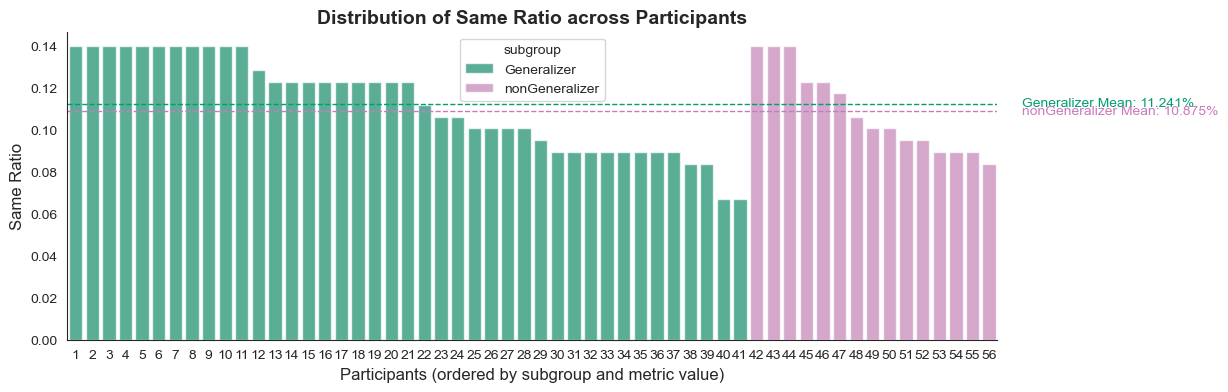

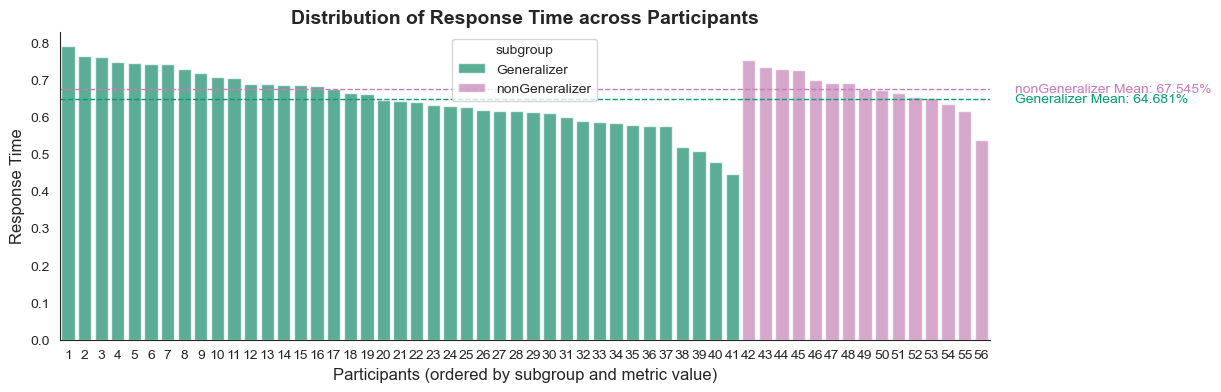

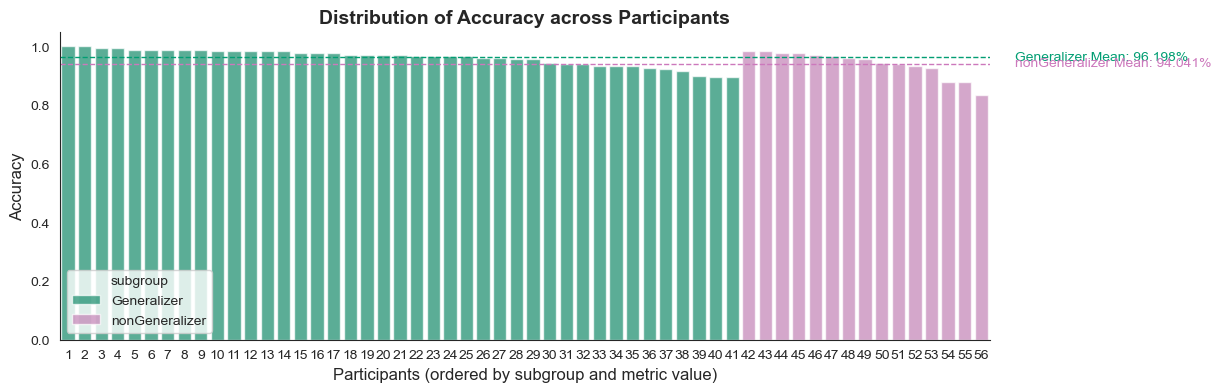

In [25]:
# plot the distribution of:
# 1) how many trials out of the total trials are "same as previous"
# 2) accuracy
# plot as individual bars, x axis is participant, y axis is the metric value, ordered by the subgroup then metric value, coloured by subgroup
metrics_to_plot = ["same_ratio","response_time","accuracy"]
for metric in metrics_to_plot:
    fig, ax = plt.subplots(figsize=(12,4))
    plotdf = lzer_bhav_metrics_df.sort_values(by=["subgroup", metric], ascending=[True, False]).copy()
    plotdf["participant_order"] = range(1, len(plotdf) + 1)
    sns.barplot(data=plotdf, x="participant_order", y=metric, hue="subgroup", palette=participantgrouphex, dodge=False, ax=ax,alpha=0.7)
    # add horizontal lines for group means
    for subgroup, gdf in plotdf.groupby("subgroup"):
        mean_val = gdf[metric].mean()
        ax.axhline(mean_val, color=participantgrouphex[subgroup], linestyle='--', linewidth=1)
        ax.text(len(plotdf) + 1, mean_val, f'{subgroup} Mean: {mean_val*100:.3f}%', color=participantgrouphex[subgroup], va='center', fontsize=10)
    ax.set_xlabel("Participants (ordered by subgroup and metric value)", fontdict={"size":12})
    ax.set_ylabel(metric.replace("_", " ").title(), fontdict={"size":12})   
    ax.set_title(f"Distribution of {metric.replace('_', ' ').title()} across Participants", fontdict={"size":14, "weight":"bold"})
    sns.despine()


In [26]:
# compute the s.e.m. and range for each metric by subgroup
beh_summary = []
for subgroup, gdf in lzer_bhav_metrics_df.groupby("subgroup"):
    for metric in metrics_to_plot:
        mean_val = gdf[metric].mean()
        sem_val = scipy.stats.sem(gdf[metric].values, nan_policy='omit')
        min_val = gdf[metric].min()
        max_val = gdf[metric].max()
        beh_summary.append({
            "subgroup": subgroup,
            "metric": metric,
            "mean": mean_val*100 if metric!="response_time" else mean_val,
            "sem": sem_val*100 if metric!="response_time" else sem_val,
            "min": min_val*100 if metric!="response_time" else min_val,
            "max": max_val*100 if metric!="response_time" else max_val
        })
beh_summary_df = pd.DataFrame(beh_summary)
beh_summary_df

,subgroup,metric,mean,sem,min,max
0,Generalizer,same_ratio,11.241314,0.352354,6.703911,13.966480
1,Generalizer,response_time,0.646812,0.012400,0.445463,0.789977
2,Generalizer,accuracy,96.198392,0.456791,89.385475,100.000000
3,nonGeneralizer,same_ratio,10.875233,0.516835,8.379888,13.966480
4,nonGeneralizer,response_time,0.675449,0.014143,0.537227,0.754125
5,nonGeneralizer,accuracy,94.040968,1.168890,83.240223,98.324022


p-value for same_ratio between groups:  0.6133386661333866
p-value for response_time between groups:  0.20537946205379462
p-value for accuracy between groups:  0.059394060593940604


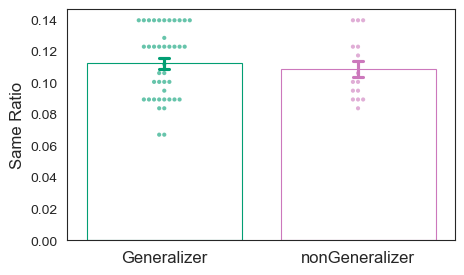

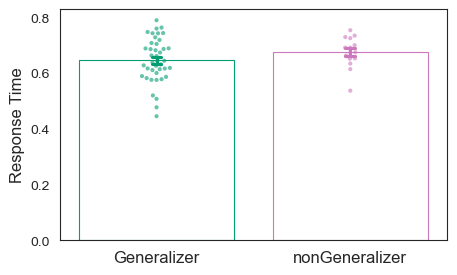

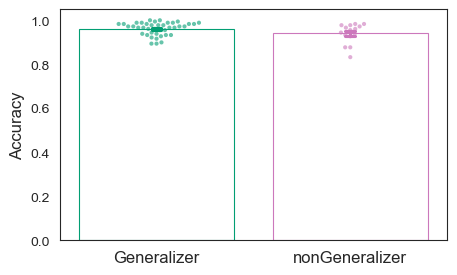

In [27]:
# plot the barplot of:
for metric in metrics_to_plot:
    fig, ax = plt.subplots(figsize=(5,3))
    sns.swarmplot(
        lzer_bhav_metrics_df,
        x="subgroup",
        y=metric,
        hue="subgroup",
        palette=participantgrouphex,
        dodge=False,
        ax=ax,
        size=3,
        alpha=0.6,
        edgecolor="none",
        linewidth=0.5
        )
    sns.barplot(
        lzer_bhav_metrics_df,
        x="subgroup",
        y=metric,
        hue="subgroup",
        palette=participantgrouphex,
        fill=False,
        errorbar="se",
        linewidth=0.8,
        capsize=0.05,
        ax=ax
        )
    ax.set_xlabel("")
    ax.set_ylabel(metric.replace("_", " ").title(), fontdict={"size":12})   
    # make x axis tick labels bigger
    ax.tick_params(axis='x', labelsize=12)
    # show stat for between group comparison
    pval = ttestindsamp_equiv_permutation(
        lzer_bhav_metrics_df[lzer_bhav_metrics_df.subgroup=="Generalizer"][metric].values,
        lzer_bhav_metrics_df[lzer_bhav_metrics_df.subgroup=="nonGeneralizer"][metric].values,
        alternative="two-sided"
    )
    print(f"p-value for {metric} between groups: ", pval)
    if pval<0.05:
        pval_annot = gen_pval_annot(pval)
        # add the pval annotation to the plot
        ax.text(0.5, ax.get_ylim()[1] + 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0]), pval_annot, ha='center', va='bottom', color='k', fontsize=14)
    #ax.set_title(f"{metric.replace('_', ' ').title()} by Participant Group", fontdict={"size":14, "weight":"bold"})

# Design Efficiency

In [1]:
import hdf5storage
from zpyhelper.MVPA.rdm import lower_tri

In [9]:
filename = 'TreasureHunt_DesignMatrix.mat'
data = hdf5storage.loadmat(filename)
S = data                                
# drill down to the field & cell index that contains the value
# e.g. if S['f_mats1'][0] is the matrix:
mat = S['xX'].squeeze()[0][0]                         # adjust indexing to match your structure
val = float(mat.ravel()[0])                   # first element example
print("hdf5storage value repr:", repr(val))
print("hdf5storage formatted:", "{:.16f}".format(val))


hdf5storage value repr: 0.0
hdf5storage formatted: 0.0000000000000000


In [20]:
desMat = {"sessrows":[x.flatten().astype(int) for x in data["sessSEIDX"].squeeze()],
          "xKXs":  list(data["xX"].squeeze()), 
          "xX":    list(data["xX"].squeeze()), 
          "name":  [[r[0][0] for r in x.flatten()] for x in data["name"].squeeze()], 
          "subid": [x[0][0] for x in data["subid"].squeeze()]}

In [21]:
corr_mats = np.full((len(desMat['subid']), 4, 26, 26), fill_value=0.0) # for four runs
desg_mats  = [[] for _ in range(len(desMat['subid']))]
for i, (sid, sidx, m,regnames) in enumerate(zip(desMat['subid'], desMat['sessrows'], desMat['xX'], desMat['name'])):
    # print(regnames)
    for s in range(4): # loop over runs
        # pick only the regressors of interest
        cmask = np.isin(regnames, [f's{s+1}_stim%02d' % d for d in range(25)] + [f's{s+1}_response', f's{s+1}_responsexmoving_x^1', f's{s+1}_responsexmoving_y^1'])
        keepcs = np.array(regnames)[cmask]
        tmask = np.arange(sidx[s]-1, sidx[s+1]) if s==0 else np.arange(sidx[s], sidx[s+1])  # matlab to python indexing
        assert np.sum(cmask) == 26, f"Subject {sid}, run {s+1}: expected 26 regressors, got {np.sum(cmask)}"
        des_mat_tmp = m[tmask,:][:,cmask]
        print(f"Subject {sid}, run {s+1}: design matrix shape {des_mat_tmp.shape}")
        corr_mats[i,s,:,:] = np.corrcoef(des_mat_tmp.T)
        desg_mats[i].append(des_mat_tmp)
    
        print(f"Mean Correlation for subject {i}, run {s}: {np.nanmean(lower_tri(corr_mats[i,s,:,:])[0])}")

Subject sub001, run 1: design matrix shape (296, 26)
Mean Correlation for subject 0, run 0: -0.027357483454536882
Subject sub001, run 2: design matrix shape (296, 26)
Mean Correlation for subject 0, run 1: -0.025434875368904965
Subject sub001, run 3: design matrix shape (296, 26)
Mean Correlation for subject 0, run 2: -0.02498397949424777
Subject sub001, run 4: design matrix shape (296, 26)
Mean Correlation for subject 0, run 3: -0.026034302503071715
Subject sub002, run 1: design matrix shape (296, 26)
Mean Correlation for subject 1, run 0: -0.02536610312163828
Subject sub002, run 2: design matrix shape (296, 26)
Mean Correlation for subject 1, run 1: -0.027015375810443897
Subject sub002, run 3: design matrix shape (296, 26)
Mean Correlation for subject 1, run 2: -0.026630798501235918
Subject sub002, run 4: design matrix shape (296, 26)
Mean Correlation for subject 1, run 3: -0.02525613062869087
Subject sub003, run 1: design matrix shape (296, 26)
Mean Correlation for subject 2, run 0:

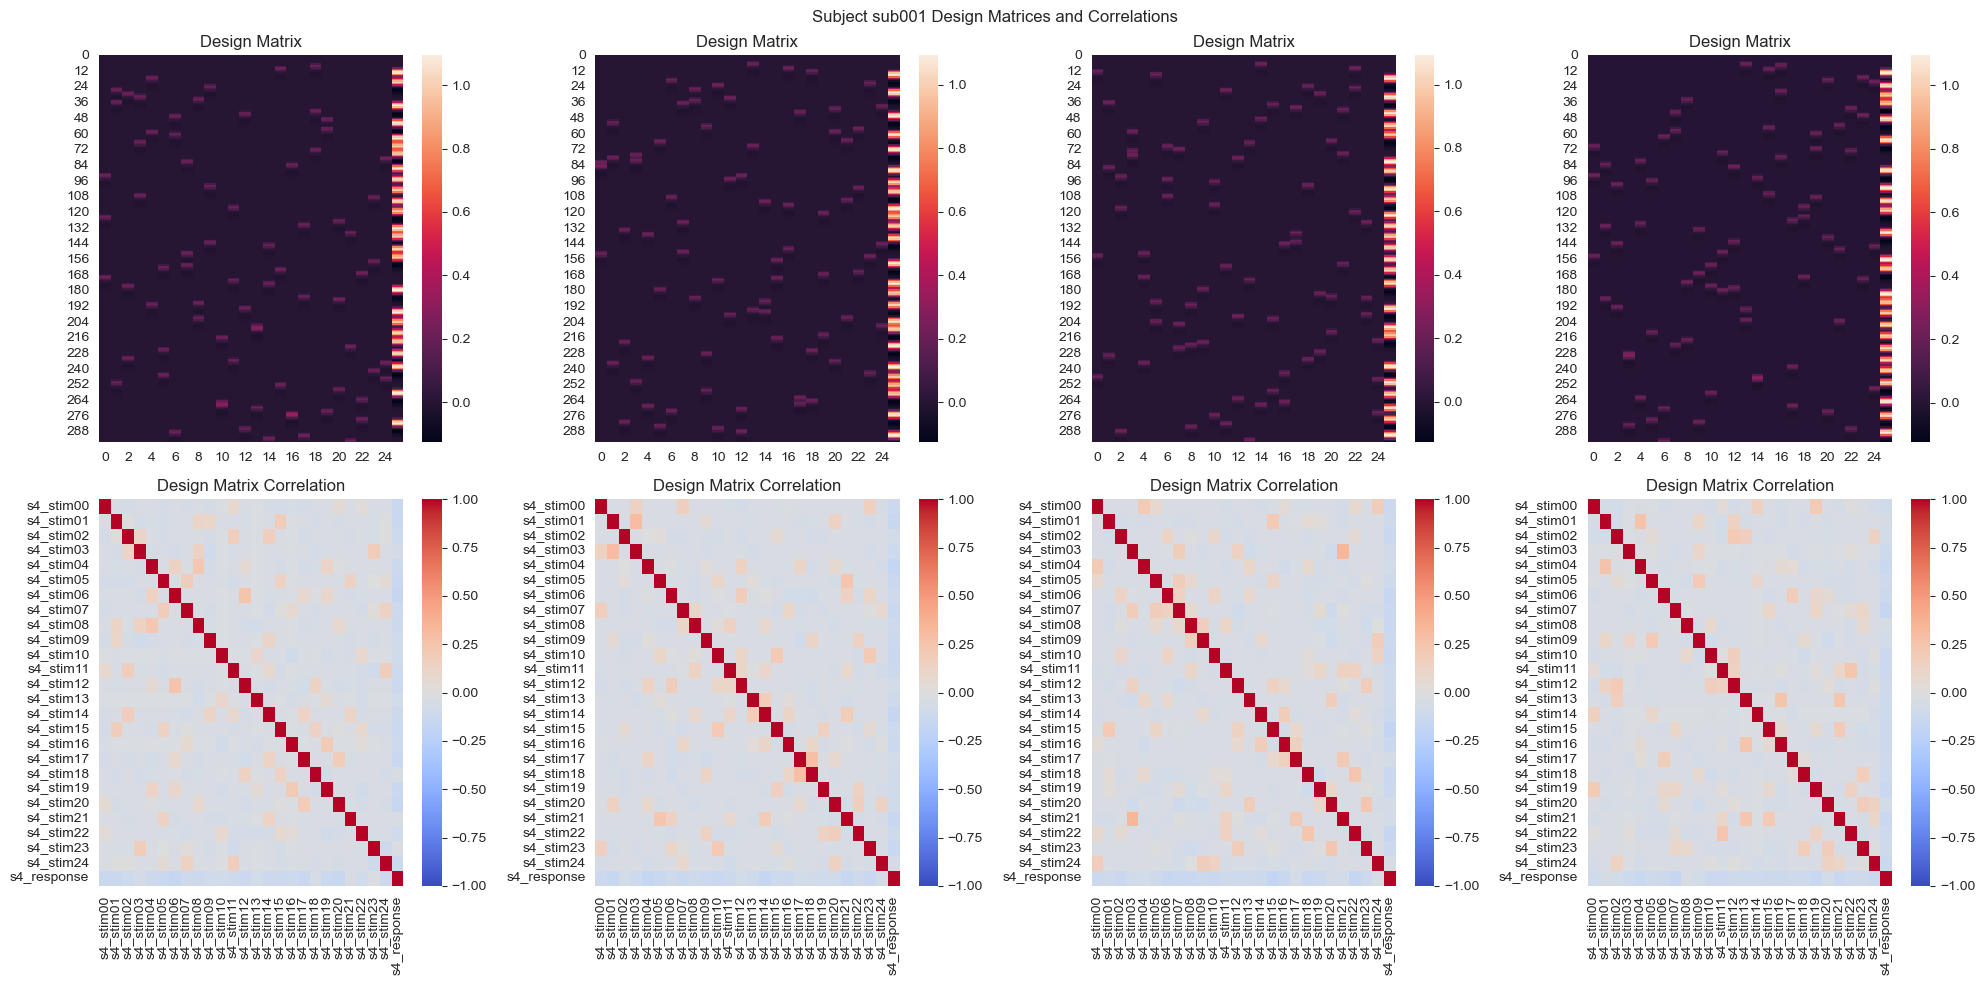

In [22]:
sid = 0  # pick a subject to plot the design matrix and correlation matrices
fig,axes = plt.subplots(2,4, figsize=(20,5*2))
for s in range(4):
    sns.heatmap(desg_mats[sid][s], ax=axes[0,s])
    sns.heatmap(corr_mats[sid,s,:,:], xticklabels=keepcs, yticklabels=keepcs, vmin=-1, vmax=1, cmap='coolwarm', ax=axes[1,s])
    axes[0,s].set_title(f"Design Matrix")
    axes[1,s].set_title(f"Design Matrix Correlation")
fig.suptitle(f"Subject {desMat['subid'][sid]} Design Matrices and Correlations")
fig.tight_layout()

In [23]:
import matplotlib as mpl
font_paths = mpl.font_manager.findSystemFonts()
mpl.font_manager.get_font_names()
sns.set_style('white',rc = dict(font='Arial'))  # set font globally for seaborn


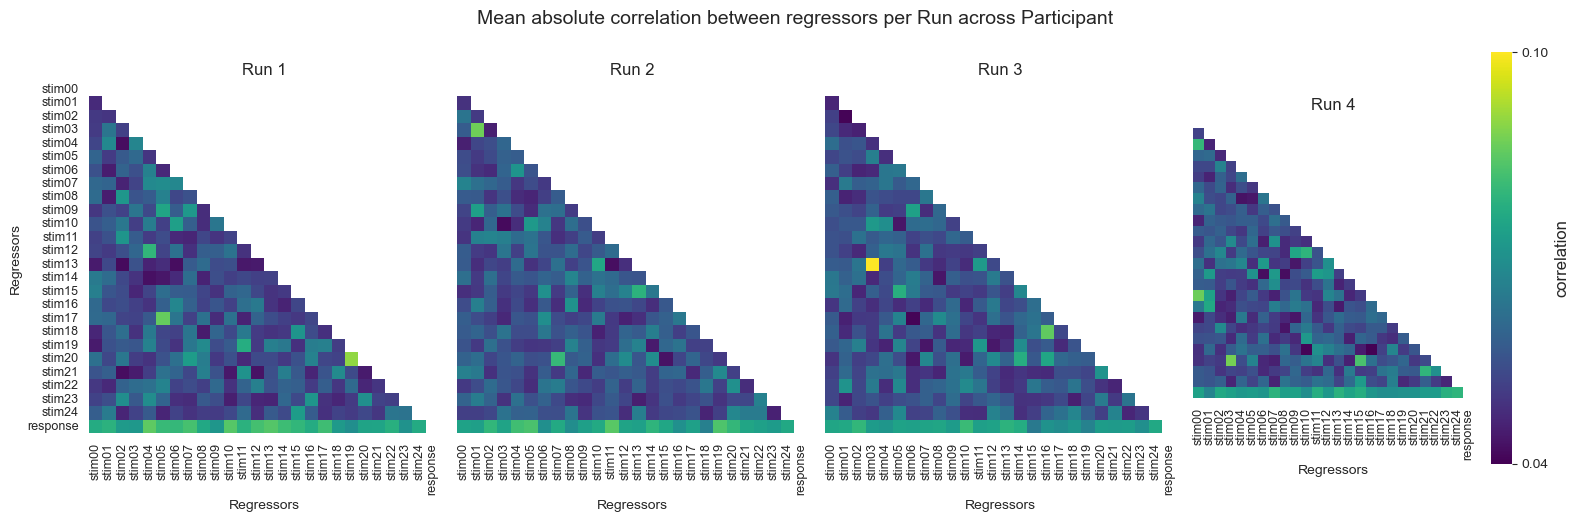

In [24]:
# calculate the mean correlation matrices across subjects, per run
fig, axes = plt.subplots(1,4, figsize=(16,5))
sess_corr_means = [np.nanmean(np.abs(corr_mats[:,s,:,:]),axis=0) for s in range(4)]
min_corr, max_corr = np.min([lower_tri(c)[0] for c in sess_corr_means]), np.max([lower_tri(c)[0] for c in sess_corr_means])
for s in range(4):
    plt_mat = np.full_like(sess_corr_means[s], fill_value=np.nan)
    plt_mat[lower_tri(sess_corr_means[s])[1]] = lower_tri(sess_corr_means[s])[0]
    sns.heatmap(plt_mat, 
                xticklabels=[x.replace("s4_","") for x in keepcs], 
                yticklabels=[x.replace("s4_","") for x in keepcs] if s==0 else False, 
                vmin=min_corr, vmax=max_corr, cmap='viridis', 
                square=True,
                ax=axes[s],
                cbar_kws={'label': 'correlation',
                          'ticks':[min_corr, 0, max_corr]
                          } ,
                cbar=s==3)
    if s==3:
        axes[s].collections[0].colorbar.set_ticklabels([f"{min_corr:.2f}",f"0",f"{max_corr:.2f}"])
        axes[s].collections[0].colorbar.ax.yaxis.label.set_size(12)
    axes[s].tick_params(axis="x",which="major",labelsize=9)
    axes[s].tick_params(axis="y",which="major",labelsize=9)
    axes[s].set_title(f"Run {s+1}")
    axes[s].set_xlabel("Regressors")


axes[0].set_ylabel("Regressors")
fig.suptitle("Mean absolute correlation between regressors per Run across Participant", fontsize=14)
fig.tight_layout()

In [25]:
# get the mean absolute correlation per subject, per run for the response regressor
mean_abs_corrs_response = np.full((len(desMat['subid']), 25*4), fill_value=np.nan)
for i in range(len(desMat['subid'])):
    for s in range(4):
        # get the last row of the corr mat at the current run 
        corr_mat_run = corr_mats[i,s,:,:]
        resp_corrs   = corr_mat_run[-1,:]
        # exclude self-correlation
        mean_abs_corrs_response[i, s*25:(s+1)*25] = np.abs(resp_corrs[:-1])
# print mean, max, min as .3f
print("Mean absolute correlation with response regressor across subjects and runs: {:.3f}".format(np.nanmean(mean_abs_corrs_response)))
print("Max absolute correlation with response regressor across subjects and runs: {:.3f}".format(np.nanmax(mean_abs_corrs_response)))



Mean absolute correlation with response regressor across subjects and runs: 0.076
Max absolute correlation with response regressor across subjects and runs: 0.183


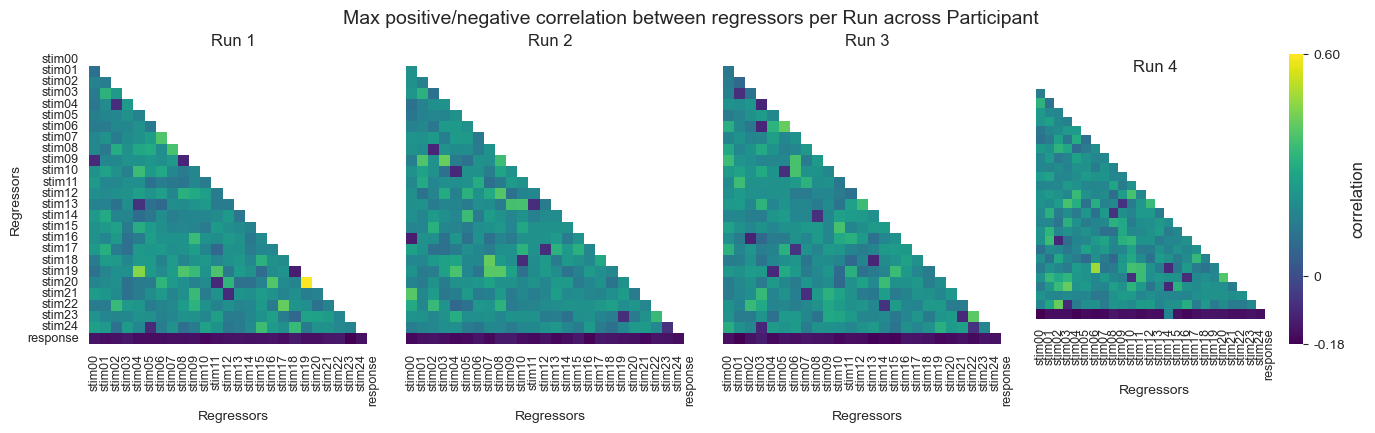

In [26]:
# calculate the max correlation matrices across subjects, per run
fig, axes = plt.subplots(1,4, figsize=(14,4))
# get the max correlation values per run across subjects irrespective of sign, but plot with sign
sess_corr_maxs = []
for s in range(4):
    max_corr_mat = np.zeros_like(corr_mats[0,s,:,:])
    for i in range(max_corr_mat.shape[0]):
        for j in range(max_corr_mat.shape[1]):
            vals = corr_mats[:,s,i,j]
            max_idx = np.argmax(np.abs(vals))
            max_corr_mat[i,j] = vals[max_idx]
    sess_corr_maxs.append(max_corr_mat)

min_corr, max_corr = np.min([lower_tri(c)[0] for c in sess_corr_maxs]), np.max([lower_tri(c)[0] for c in sess_corr_maxs])
for s in range(4):
    plt_mat = np.full_like(sess_corr_maxs[s], fill_value=np.nan)
    plt_mat[lower_tri(sess_corr_maxs[s])[1]] = lower_tri(sess_corr_maxs[s])[0]
    sns.heatmap(plt_mat, 
                xticklabels=[x.replace("s4_","") for x in keepcs], 
                yticklabels=[x.replace("s4_","") for x in keepcs] if s==0 else False, 
                vmin=min_corr, vmax=max_corr, cmap='viridis', 
                ax=axes[s],
                square=True,
                cbar_kws={'label': 'correlation',
                          'ticks':[min_corr, 0, max_corr]
                          } ,
                cbar=s==3)
    if s==3:
        axes[s].collections[0].colorbar.set_ticklabels([f"{min_corr:.2f}",f"0",f"{max_corr:.2f}"])
        axes[s].collections[0].colorbar.ax.yaxis.label.set_size(12)
    axes[s].tick_params(axis="x",which="major",labelsize=9)
    axes[s].tick_params(axis="y",which="major",labelsize=9)
    axes[s].set_title(f"Run {s+1}")
    axes[s].set_xlabel("Regressors")


axes[0].set_ylabel("Regressors")
fig.suptitle("Max positive/negative correlation between regressors per Run across Participant",fontsize=14)
fig.tight_layout()

In [27]:
# print the min and max correlation values observed
min_corr_mats, max_corr_mats, mean_corr_mats = [], [], []
for s in range(4):
    max_corr_mat = np.zeros_like(corr_mats[0,s,:,:])
    min_corr_mat = np.zeros_like(corr_mats[0,s,:,:])
    mean_corr_mat = np.zeros_like(corr_mats[0,s,:,:])
    for i in range(max_corr_mat.shape[0]):
        for j in range(max_corr_mat.shape[1]):
            vals = corr_mats[:,s,i,j]
            max_idx = np.argmax(np.abs(vals))
            max_corr_mat[i,j] = vals[max_idx]
            min_idx = np.argmin(vals)
            min_corr_mat[i,j] = vals[min_idx]
            mean_corr_mat[i,j] = np.nanmean(np.abs(vals))
    print(f"Run {s+1}: min observed corr {np.min(lower_tri(min_corr_mat)[0]):.4f}, \
            max observed corr {np.max(lower_tri(max_corr_mat)[0]):.4f}, \
            mean abs observed corr {np.nanmean(lower_tri(mean_corr_mat)[0]):.4f}")
    min_corr_mats.append(lower_tri(max_corr_mat)[0])
    max_corr_mats.append(lower_tri(max_corr_mat)[0])
    mean_corr_mats.append(lower_tri(mean_corr_mat)[0])
print(f"Across all runs:\nOverall min corr: {np.min(min_corr_mats):.4f} \
        \nOverall max corr: {np.max(max_corr_mats):.4f} \
        \nOverall mean abs corr: {np.mean(mean_corr_mats):.4f}".format())

Run 1: min observed corr -0.1803,             max observed corr 0.5992,             mean abs observed corr 0.0561
Run 2: min observed corr -0.1756,             max observed corr 0.4210,             mean abs observed corr 0.0563
Run 3: min observed corr -0.1827,             max observed corr 0.4145,             mean abs observed corr 0.0562
Run 4: min observed corr -0.1820,             max observed corr 0.4854,             mean abs observed corr 0.0561
Across all runs:
Overall min corr: -0.1827         
Overall max corr: 0.5992         
Overall mean abs corr: 0.0562


In [28]:
# calculate VIFs
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = np.full((len(desMat['subid']), 4, 26), fill_value=0.0) # for four runs

prev_m = None
for i, (sid, ms, cs) in enumerate(zip(desMat['subid'], desg_mats, corr_mats)):
    for s, m in enumerate(ms):
        print(f"Calculating VIF for subject {i}, run {s}", end="\r",flush=True)
        vif_data[i,s,:] = [variance_inflation_factor(m, i) for i in range(m.shape[1])]
        
print("min VIF across all subjects and runs:", np.min(vif_data))
print("max VIF across all subjects and runs:", np.max(vif_data))


min VIF across all subjects and runs: 1.00502119806874
max VIF across all subjects and runs: 1.6882916670595907


In [29]:
print("min VIF across all subjects and runs:", np.min(vif_data))
print("max VIF across all subjects and runs:", np.max(vif_data))
print("mean VIF across all subjects and runs:", np.mean(vif_data))

min VIF across all subjects and runs: 1.00502119806874
max VIF across all subjects and runs: 1.6882916670595907
mean VIF across all subjects and runs: 1.125055001302059


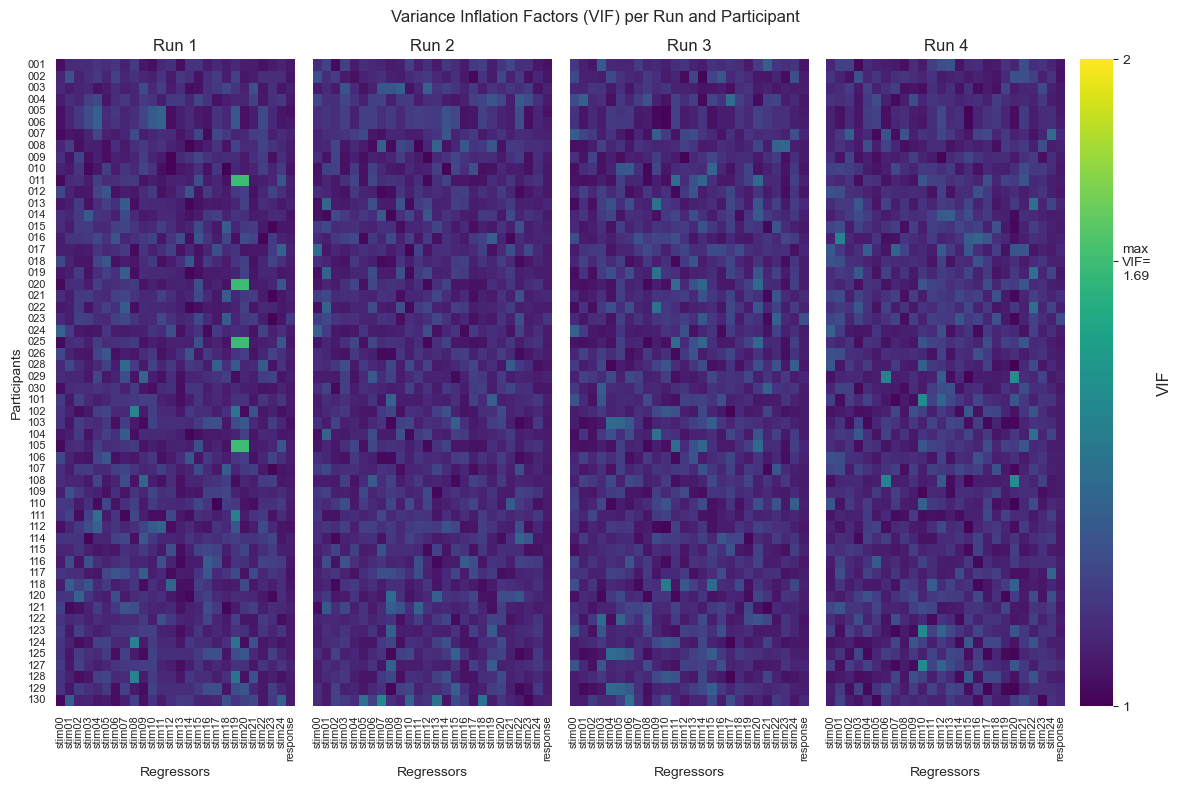

In [30]:
# plot VIFs
fig, axes = plt.subplots(1,4, figsize=(12,8),width_ratios=[1,1,1,1.25])
for s in range(4):
    sns.heatmap(vif_data[:,s,:], xticklabels=[x.replace("s4_","") for x in keepcs], 
                yticklabels=[x.replace("sub","") for x in desMat['subid']] if s==0 else False, 
                vmin=np.floor(vif_data.min()), vmax=np.ceil(vif_data.max()), cmap='viridis', 
                ax=axes[s],
                cbar_kws={'label': 'VIF','ticks':[np.floor(vif_data.min()),vif_data.max(), np.ceil(vif_data.max())]} ,
                cbar=s==3)
    # highlight very high VIFs (>3)
    if np.ceil(vif_data.max())>3:
        for i in range(vif_data[:,s,:].shape[0]):
            for j in range(vif_data[:,s,:].shape[1]):
                if vif_data[i,s,j]>3:
                    axes[s].add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='red', lw=1.5))
                    # also print the subject and regressor name
                    print(f"High VIF >3 detected: Subject {desMat['subid'][i]}, Run {s+1}, Regressor {keepcs[j]}, VIF={vif_data[i,s,j]:.2f}")
    if s==3:
        axes[s].collections[0].colorbar.set_ticklabels([f"{np.floor(vif_data.min()):.0f}",f"max\nVIF=\n{vif_data.max():.2f}",f"{np.ceil(vif_data.max()):.0f}"],
                                                       rotation = 0)
        axes[s].collections[0].colorbar.ax.yaxis.label.set_size(12)
    axes[s].tick_params(axis="x",which="major",labelsize=8)
    axes[s].tick_params(axis="y",which="major",labelsize=8)
    axes[s].set_title(f"Run {s+1}")
    axes[s].set_xlabel("Regressors")


axes[0].set_ylabel("Participants")
fig.suptitle("Variance Inflation Factors (VIF) per Run and Participant")
fig.tight_layout()